In [2]:
from pathlib import Path
import importlib.util
import sys
import hashlib
import json
import platform
from dataclasses import asdict, replace
from datetime import datetime, timezone
from importlib.metadata import version
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss
from scipy.special import gammaln
from scipy.stats import gennorm
from threadpoolctl import threadpool_limits

cwd = Path.cwd().resolve()
MODEL_FILE = next(
    (p for folder in (cwd, *cwd.parents)
     for p in (folder / "VGGMM_Merge_Refit.py",
               folder / "GGMM" / "VGGMM_Merge_Refit.py")
     if p.is_file()), None
)
if MODEL_FILE is None:
    raise FileNotFoundError(
        "vggmm_merge_refit.py를 찾지 못했습니다. 모델과 노트북을 함께 두고 "
        "VS Code에서 저장소 폴더를 여세요. 현재 작업폴더: " + str(cwd)
    )

spec = importlib.util.spec_from_file_location("vggmm_merge_refit", MODEL_FILE)
vg = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = vg
spec.loader.exec_module(vg)

Mixture = vg.Mixture
VGGMMConfig = vg.VGGMMConfig
VariationalGGMM = vg.VariationalGGMM

N = 5000
SAMPLE_SEED = 20260912
CAPS = (10, 11, 12, 13, 14, 15)
INITIAL_SHAPE_MODE = "moment"  # 원본 설정. 초기 b=2 대조는 "shape2".
INCLUDE_VGM = True
SHOW_PLOTS = True
OUTPUT_ROOT = Path("results")

BASE_CONFIG = VGGMMConfig(
    initial_shape_mode=INITIAL_SHAPE_MODE,
    enable_merge=True,
)

print("불러온 모델:", MODEL_FILE)
print("초기 shape:", INITIAL_SHAPE_MODE, "| VGM 비교:", INCLUDE_VGM)

불러온 모델: /Users/sungwon/SungwonDS.github.io/GGMM/VGGMM_Merge_Refit.py
초기 shape: moment | VGM 비교: True


In [3]:
def sample_mixture(truth, n, seed):
    rng = np.random.default_rng(seed)
    labels = rng.choice(truth.k, size=n, p=truth.weights)
    return np.asarray(gennorm.rvs(
        truth.shapes[labels],
        loc=truth.means[labels],
        scale=truth.scales[labels],
        random_state=rng,
    ), dtype=float)


truth = Mixture(
    weights=[.2, .3, .5],
    means=[-5., 0., 6.],
    scales=[1.2, 1.6, 2.],
    shapes=[1.5, 4., 8.],
)

X = sample_mixture(truth, N, SAMPLE_SEED)
X.setflags(write=False)
SAMPLE_SHA256 = hashlib.sha256(
    np.asarray(X, dtype="<f8").tobytes()
).hexdigest()

print(
    f"N={len(X):,}; seed={SAMPLE_SEED}; true K={truth.k}; "
    f"mean={X.mean():.9f}; sd={X.std():.9f}"
)

N=5,000; seed=20260912; true K=3; mean=1.951268356; sd=4.477863802


In [4]:
def active_view(full, threshold):
    keep = full.weights > threshold
    retained = float(full.weights[keep].sum())
    excluded = float(full.weights[~keep].sum())

    density = (
        Mixture(
            full.weights[keep] / retained,
            full.means[keep],
            full.scales[keep],
            full.shapes[keep],
        )
        if keep.any() else None
    )
    return density, int(keep.sum()), excluded


_LEGENDRE = {order: leggauss(order) for order in (32, 64)}


def density_errors(
    truth, fitted, tail=1e-9,
    atol=1e-7, rtol=1e-5, max_refinement=16,
):
    """Adaptive IAE/ISE with quadrature error estimates and tail bounds."""
    probabilities = np.array([
        tail, 1e-6, 1e-4, .001, .01, .1, .25, .5,
        .75, .9, .99, .999, 1-1e-4, 1-1e-6, 1-tail,
    ])
    points = np.unique(np.concatenate([
        gennorm.ppf(
            probabilities[:, None],
            m.shapes,
            loc=m.means,
            scale=m.scales,
        ).ravel()
        for m in (truth, fitted)
    ]))
    if not np.isfinite(points).all():
        raise FloatingPointError("Evaluation quantiles cannot be represented.")

    left, right = points[:-1], points[1:]
    n_panels = len(left)
    depth = np.zeros(n_panels, int)
    total, error = np.zeros(2), np.zeros(2)
    unresolved = 0

    def panel(l, r, order):
        nodes, weights = _LEGENDRE[order]
        mid, half = l/2+r/2, (r-l)/2
        xx = mid[:, None] + half[:, None]*nodes
        delta = (
            fitted.pdf(xx.ravel()) - truth.pdf(xx.ravel())
        ).reshape(xx.shape)
        return np.c_[
            np.abs(delta) @ weights,
            delta**2 @ weights,
        ] * half[:, None]

    while len(left):
        low = panel(left, right, 32)
        high = panel(left, right, 64)
        err = np.abs(high-low)
        good = np.all(
            err <= atol/n_panels/(2.**depth[:, None]) + rtol*np.abs(high),
            axis=1,
        )
        stopped = depth >= max_refinement
        accept = good | stopped

        total += high[accept].sum(axis=0)
        error += err[accept].sum(axis=0)
        unresolved += int(np.sum(stopped & ~good))

        ll, rr, dd = left[~accept], right[~accept], depth[~accept]
        mid = ll/2+rr/2
        left, right, depth = (
            np.r_[ll, mid],
            np.r_[mid, rr],
            np.r_[dd+1, dd+1],
        )

    lo, hi = points[0], points[-1]

    def omitted(model):
        return float(np.clip(
            model.cdf([lo])[0] + 1 - model.cdf([hi])[0], 0, 1
        ))

    def peak(model):
        return float(np.sum(
            model.weights * np.exp(
                -np.log(2) - np.log(model.scales)
                - gammaln(1+1/model.shapes)
            )
        ))

    tt, tf = omitted(truth), omitted(fitted)
    return dict(
        IAE=float(total[0]),
        ISE=float(total[1]),
        IAE_quad_error=float(error[0]),
        ISE_quad_error=float(error[1]),
        IAE_tail_upper=tt+tf,
        ISE_tail_upper=peak(truth)*tt + peak(fitted)*tf,
        Quadrature_OK=bool(
            unresolved == 0
            and np.all(error <= atol + rtol*np.abs(total))
        ),
    )


def check_mathematics():
    xx, mean, sd = np.array([-3., -.1, 0., 2., 10.]), .4, .7
    np.testing.assert_allclose(
        np.exp(vg.normal_log_abs_moment(xx, mean, np.log(sd), 2.)),
        (xx-mean)**2 + sd**2,
        rtol=2e-13,
    )

    cfg = BASE_CONFIG
    r = np.array([.1, .7, .4, .8, .2])
    y = np.array([mean, np.log(sd), np.log(1.7)])
    profiled, a, lb, _ = vg.component_profile(y, xx, r, cfg)
    expected = vg.expected_log_components(
        xx, y[None, :], np.array([a]), np.array([lb])
    )[:, 0]
    expanded = r @ expected - vg.normal_kl(mean, np.log(sd), cfg.mean_prior_sd)
    expanded -= vg.gamma_kl(
        a, lb, cfg.precision_prior_shape, cfg.precision_prior_rate
    )
    np.testing.assert_allclose(
        profiled, expanded, rtol=2e-13, atol=1e-12
    )

    for nk in (np.array([100., 0., 40., 2.]), np.array([5.])):
        sa, sb = vg.stick_posterior(nk, cfg.concentration)
        w, elogw = vg.stick_statistics(sa, sb)
        np.testing.assert_allclose(w.sum(), 1., atol=1e-14)
        assert np.all(elogw <= np.log(w)+1e-10)

    print("Math checks passed: normal moment, Gamma profile/ELBO, sticks.")


check_mathematics()

Math checks passed: normal moment, Gamma profile/ELBO, sticks.


In [5]:
def active_view(full, threshold):
    keep = full.weights > threshold
    retained = float(full.weights[keep].sum())
    excluded = float(full.weights[~keep].sum())

    density = (
        Mixture(
            full.weights[keep] / retained,
            full.means[keep],
            full.scales[keep],
            full.shapes[keep],
        )
        if keep.any() else None
    )
    return density, int(keep.sum()), excluded


_LEGENDRE = {order: leggauss(order) for order in (32, 64)}


def density_errors(
    truth, fitted, tail=1e-9,
    atol=1e-7, rtol=1e-5, max_refinement=16,
):
    """Adaptive IAE/ISE with quadrature error estimates and tail bounds."""
    probabilities = np.array([
        tail, 1e-6, 1e-4, .001, .01, .1, .25, .5,
        .75, .9, .99, .999, 1-1e-4, 1-1e-6, 1-tail,
    ])
    points = np.unique(np.concatenate([
        gennorm.ppf(
            probabilities[:, None],
            m.shapes,
            loc=m.means,
            scale=m.scales,
        ).ravel()
        for m in (truth, fitted)
    ]))
    if not np.isfinite(points).all():
        raise FloatingPointError("Evaluation quantiles cannot be represented.")

    left, right = points[:-1], points[1:]
    n_panels = len(left)
    depth = np.zeros(n_panels, int)
    total, error = np.zeros(2), np.zeros(2)
    unresolved = 0

    def panel(l, r, order):
        nodes, weights = _LEGENDRE[order]
        mid, half = l/2+r/2, (r-l)/2
        xx = mid[:, None] + half[:, None]*nodes
        delta = (
            fitted.pdf(xx.ravel()) - truth.pdf(xx.ravel())
        ).reshape(xx.shape)
        return np.c_[
            np.abs(delta) @ weights,
            delta**2 @ weights,
        ] * half[:, None]

    while len(left):
        low = panel(left, right, 32)
        high = panel(left, right, 64)
        err = np.abs(high-low)
        good = np.all(
            err <= atol/n_panels/(2.**depth[:, None]) + rtol*np.abs(high),
            axis=1,
        )
        stopped = depth >= max_refinement
        accept = good | stopped

        total += high[accept].sum(axis=0)
        error += err[accept].sum(axis=0)
        unresolved += int(np.sum(stopped & ~good))

        ll, rr, dd = left[~accept], right[~accept], depth[~accept]
        mid = ll/2+rr/2
        left, right, depth = (
            np.r_[ll, mid],
            np.r_[mid, rr],
            np.r_[dd+1, dd+1],
        )

    lo, hi = points[0], points[-1]

    def omitted(model):
        return float(np.clip(
            model.cdf([lo])[0] + 1 - model.cdf([hi])[0], 0, 1
        ))

    def peak(model):
        return float(np.sum(
            model.weights * np.exp(
                -np.log(2) - np.log(model.scales)
                - gammaln(1+1/model.shapes)
            )
        ))

    tt, tf = omitted(truth), omitted(fitted)
    return dict(
        IAE=float(total[0]),
        ISE=float(total[1]),
        IAE_quad_error=float(error[0]),
        ISE_quad_error=float(error[1]),
        IAE_tail_upper=tt+tf,
        ISE_tail_upper=peak(truth)*tt + peak(fitted)*tf,
        Quadrature_OK=bool(
            unresolved == 0
            and np.all(error <= atol + rtol*np.abs(total))
        ),
    )


def check_mathematics():
    xx, mean, sd = np.array([-3., -.1, 0., 2., 10.]), .4, .7
    np.testing.assert_allclose(
        np.exp(vg.normal_log_abs_moment(xx, mean, np.log(sd), 2.)),
        (xx-mean)**2 + sd**2,
        rtol=2e-13,
    )

    cfg = BASE_CONFIG
    r = np.array([.1, .7, .4, .8, .2])
    y = np.array([mean, np.log(sd), np.log(1.7)])
    profiled, a, lb, _ = vg.component_profile(y, xx, r, cfg)
    expected = vg.expected_log_components(
        xx, y[None, :], np.array([a]), np.array([lb])
    )[:, 0]
    expanded = r @ expected - vg.normal_kl(mean, np.log(sd), cfg.mean_prior_sd)
    expanded -= vg.gamma_kl(
        a, lb, cfg.precision_prior_shape, cfg.precision_prior_rate
    )
    np.testing.assert_allclose(
        profiled, expanded, rtol=2e-13, atol=1e-12
    )

    for nk in (np.array([100., 0., 40., 2.]), np.array([5.])):
        sa, sb = vg.stick_posterior(nk, cfg.concentration)
        w, elogw = vg.stick_statistics(sa, sb)
        np.testing.assert_allclose(w.sum(), 1., atol=1e-14)
        assert np.all(elogw <= np.log(w)+1e-10)

    print("Math checks passed: normal moment, Gamma profile/ELBO, sticks.")


check_mathematics()

Math checks passed: normal moment, Gamma profile/ELBO, sticks.


In [6]:
def fit_vgm(x, cap, cfg):
    from sklearn.mixture import BayesianGaussianMixture

    estimator = BayesianGaussianMixture(
        n_components=cap,
        covariance_type="full",
        weight_concentration_prior_type="dirichlet_process",
        weight_concentration_prior=cfg.concentration,
        init_params="kmeans",
        n_init=1,
        max_iter=1500,
        tol=1e-3,
        reg_covar=1e-6,
        random_state=27,
    )
    started = perf_counter()
    with threadpool_limits(limits=1):
        estimator.fit(np.array(x, copy=True).reshape(-1, 1))

    full = Mixture(
        estimator.weights_/estimator.weights_.sum(),
        estimator.means_[:, 0],
        np.sqrt(2*estimator.covariances_[:, 0, 0]),
        np.full(cap, 2.),
    )
    return dict(
        full=full,
        fit_seconds=perf_counter()-started,
        converged=bool(estimator.converged_),
    )


def show_table(frame):
    try:
        from IPython import get_ipython
        from IPython.display import display
        if get_ipython() is not None:
            display(frame)
            return
    except ImportError:
        pass
    print(frame.to_string(index=False, float_format=lambda v: f"{v:.7g}"))


def evaluate_density(
    method, cap, full, x, reference, cfg, run, fit_s,
    accepted_merges=0, merge_stop_reason="disabled", failed_starts=0,
):
    started = perf_counter()
    active, k, excluded = active_view(full, cfg.active_threshold)
    if active is None:
        raise RuntimeError("No active density at the reporting threshold.")

    full_errors = density_errors(reference, full)
    errors = density_errors(reference, active)

    row = dict(
        Method=method, Max_K=cap, Active_K=k, Full_slots=full.k,
        Excluded_mass=excluded,
        IAE=errors["IAE"], ISE=errors["ISE"],
        IAE_full=full_errors["IAE"], ISE_full=full_errors["ISE"],
        Quadrature_OK=bool(
            errors["Quadrature_OK"] and full_errors["Quadrature_OK"]
        ),
        ELBO_per_observation=run["elbo"]/len(x),
        LL_full_per_observation=float(full.logpdf(x).mean()),
        Converged=run["converged"],
        Inner_nonconverged=run["inner_nonconverged"],
        Accepted_merges=accepted_merges,
        Merge_stop_reason=merge_stop_reason,
        Fit_s=fit_s,
        Failed_initial_starts=failed_starts,
        IAE_quad_error=errors["IAE_quad_error"],
        ISE_quad_error=errors["ISE_quad_error"],
        IAE_tail_upper=errors["IAE_tail_upper"],
        ISE_tail_upper=errors["ISE_tail_upper"],
        Evaluation_s=perf_counter()-started,
    )
    return row, active


def run_cap(x, cap, cfg, reference, output_dir, include_vgm=True):
    current = replace(cfg, max_components=cap)
    print(
        f"\nmax_K={cap}: baseline + merge ({cfg.initial_shape_mode})",
        flush=True,
    )
    with threadpool_limits(limits=1):
        model = VariationalGGMM(current).fit(x)

    rows, components, traces, starts, timing_rows, records = [], [], [], [], [], []
    stages = [
        ("VGGMM-base", model.baseline_run_, model.baseline_density_,
         model.baseline_seconds_, 0, "disabled"),
        ("VGGMM-merge", model.final_run_, model.full_density_,
         model.fit_seconds_, model.accepted_merges_, model.merge_stop_reason_),
    ]

    for method, run, full, seconds, accepted, stop_reason in stages:
        row, active = evaluate_density(
            method, cap, full, x, reference, cfg, run, seconds,
            accepted_merges=accepted,
            merge_stop_reason=stop_reason,
            failed_starts=len(model.failed_starts_),
        )
        rows.append(row)
        records.append(dict(method=method, cap=cap, full=full, active=active))
        nk = run["state"]["r"].sum(axis=0)

        for k in range(full.k):
            components.append(dict(
                Method=method, Max_K=cap, Component=k,
                Weight=full.weights[k], Mean=full.means[k],
                Scale=full.scales[k], Shape=full.shapes[k],
                Sigma=full.sigmas[k], Nk=nk[k],
                Active=bool(full.weights[k] > cfg.active_threshold),
            ))

        print(
            f"  {method}: Active_K={row['Active_K']}, "
            f"ELBO/n={row['ELBO_per_observation']:.7f}, "
            f"IAE={row['IAE']:.7f}, merges={accepted}",
            flush=True,
        )

    timing_rows.append(dict(
        Method="VGGMM-base+merge", Max_K=cap,
        **model.timing_, **model.work_,
        Evaluation_s=sum(row["Evaluation_s"] for row in rows),
    ))

    for run in model.runs_:
        starts.append(dict(
            Max_K=cap, Start=run["name"],
            Selected=bool(run is model.baseline_run_),
            Converged=run["converged"],
            ELBO_per_observation=run["elbo"]/len(x),
            Active_K=model._active_k(run["state"]),
            Inner_nonconverged=run["inner_nonconverged"],
            Stop_reason=run["reason"], Fit_s=run["seconds"],
            Initialization_s=run["Initialization_s"],
            Optimize_wall_s=run["Optimize_wall_s"],
        ))

    checkpoints = [("baseline", model.baseline_run_)] + [
        (f"accepted-{i}", run)
        for i, run in enumerate(model.merge_checkpoints_[1:], start=1)
    ]
    for stage, run in checkpoints:
        for item in run["history"]:
            traces.append(dict(Max_K=cap, Stage=stage, **item))

    if include_vgm:
        rec = fit_vgm(x, cap, cfg)
        fake_run = dict(
            elbo=np.nan, converged=rec["converged"], inner_nonconverged=0
        )
        row, active = evaluate_density(
            "VGM", cap, rec["full"], x, reference, cfg,
            fake_run, rec["fit_seconds"],
        )
        rows.append(row)
        records.append(dict(
            method="VGM", cap=cap, full=rec["full"], active=active
        ))
        timing_rows.append(dict(
            Method="VGM", Max_K=cap,
            Baseline_fit_s=rec["fit_seconds"], Merge_extra_s=0.,
            Finalization_s=0., Total_fit_s=rec["fit_seconds"],
            Evaluation_s=row["Evaluation_s"],
        ))

        full = rec["full"]
        for k in range(full.k):
            components.append(dict(
                Method="VGM", Max_K=cap, Component=k,
                Weight=full.weights[k], Mean=full.means[k],
                Scale=full.scales[k], Shape=full.shapes[k],
                Sigma=full.sigmas[k], Nk=np.nan,
                Active=bool(full.weights[k] > cfg.active_threshold),
            ))

    failed = pd.DataFrame(model.failed_starts_)
    if failed.empty and not len(failed.columns):
        failed = pd.DataFrame(columns=[
            "start", "error_type", "error",
            "Initialization_s", "Optimize_wall_s",
        ])

    result_tables = dict(
        metrics=pd.DataFrame(rows),
        components=pd.DataFrame(components),
        starts=pd.DataFrame(starts),
        traces=pd.DataFrame(traces),
        merge_log=pd.DataFrame(model.merge_log_),
        continuation_log=pd.DataFrame(model.continuation_log_),
        failed_starts=failed,
        timing=pd.DataFrame(timing_rows),
        seed_log=pd.DataFrame(model.seed_log_),
        initial_start_timing=pd.DataFrame(model.initial_start_timing_),
    )

    cap_dir = output_dir / f"cap_{cap}"
    cap_dir.mkdir(parents=True, exist_ok=True)
    for name, table in result_tables.items():
        table.to_csv(cap_dir / f"{name}.csv", index=False)

    arrays = {}
    for name, run in (
        ("baseline", model.baseline_run_),
        ("final", model.final_run_),
    ):
        arrays.update({
            f"{name}_{key}": value
            for key, value in run["state"].items()
        })
    arrays.update(center=model.center_, unit=model.unit_)
    np.savez_compressed(cap_dir / "posterior_states.npz", **arrays)

    summary = dict(
        config=asdict(current),
        baseline_selection_fallback=model.baseline_selection_fallback_,
        accepted_merges=model.accepted_merges_,
        merge_stop_reason=model.merge_stop_reason_,
        baseline_seconds=model.baseline_seconds_,
        merge_seconds=model.merge_seconds_,
        total_fit_seconds=model.fit_seconds_,
        timing=model.timing_,
        work=model.work_,
        full_slots=model.full_k_,
        threshold=cfg.active_threshold,
    )
    (cap_dir / "summary.json").write_text(
        json.dumps(summary, indent=2), encoding="utf-8"
    )
    return model, result_tables, records


def combined_tables(cap_tables):
    tables = {}
    for name in cap_tables[0][1]:
        frames = [
            table[name].assign(Max_K=cap)
            if "Max_K" not in table[name].columns else table[name]
            for cap, table in cap_tables if not table[name].empty
        ]
        tables[name] = (
            pd.concat(frames, ignore_index=True)
            if frames else pd.DataFrame(columns=cap_tables[0][1][name].columns)
        )

    rows = []
    for cap, group in tables["metrics"].groupby("Max_K", sort=True):
        by_method = group.set_index("Method")
        base = by_method.loc["VGGMM-base"]
        merge = by_method.loc["VGGMM-merge"]
        logs = tables["merge_log"]
        controls = tables["continuation_log"]
        accepted_gain, continuation_gain = 0., 0.

        if not logs.empty:
            chosen = logs[
                (logs["Max_K"] == cap)
                & logs["Accepted"].fillna(False).astype(bool)
            ]
            if not chosen.empty:
                accepted_gain = float(chosen["Gain_per_observation"].sum())

        if not controls.empty:
            used = controls[
                (controls["Max_K"] == cap)
                & controls["Used"].fillna(False).astype(bool)
            ]
            if not used.empty:
                continuation_gain = float(used["Gain_per_observation"].sum())

        merge_seconds = tables["timing"].loc[
            (tables["timing"]["Max_K"] == cap)
            & (tables["timing"]["Method"] == "VGGMM-base+merge"),
            "Merge_extra_s",
        ].iloc[0]

        rows.append(dict(
            Max_K=cap,
            Base_active_K=int(base["Active_K"]),
            Merge_active_K=int(merge["Active_K"]),
            Base_IAE=base["IAE"], Merge_IAE=merge["IAE"],
            Base_ISE=base["ISE"], Merge_ISE=merge["ISE"],
            Total_delta_ELBO_per_observation=(
                merge["ELBO_per_observation"]-base["ELBO_per_observation"]
            ),
            Accepted_merge_ELBO_gain_per_observation=accepted_gain,
            Continuation_ELBO_gain_per_observation=continuation_gain,
            Accepted_merges=int(merge["Accepted_merges"]),
            Merge_stop_reason=merge["Merge_stop_reason"],
            BaseFit_s=base["Fit_s"],
            MergeExtra_s=float(merge_seconds),
            TotalFit_s=merge["Fit_s"],
        ))

    tables["paired"] = pd.DataFrame(rows)
    return tables

In [7]:
caps = tuple(CAPS)
if not caps or len(caps) != len(set(caps)) or any(
    isinstance(k, (bool, np.bool_))
    or not isinstance(k, (int, np.integer))
    or k < 1
    for k in caps
):
    raise ValueError("CAPS는 중복 없는 양의 정수 목록이어야 합니다.")

cfg = replace(BASE_CONFIG, initial_shape_mode=INITIAL_SHAPE_MODE)
OUTPUT_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

models, cap_tables, records = {}, [], []
for cap in caps:
    model, one_table, one_records = run_cap(
        X, cap, cfg, truth, OUTPUT_DIR, INCLUDE_VGM
    )
    models[cap] = model
    cap_tables.append((cap, one_table))
    records.extend(one_records)

tables = combined_tables(cap_tables)
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

show_table(tables["metrics"][[
    "Method", "Max_K", "Active_K", "Excluded_mass", "IAE", "ISE",
    "Converged", "Inner_nonconverged", "Accepted_merges",
    "Fit_s", "Quadrature_OK",
]])
show_table(tables["paired"])
show_table(tables["timing"])

# VGGMM-merge의 Fit_s/TotalFit_s에는 기본 적합 시간이 이미 포함됩니다.
# MergeExtra_s는 병합 탐색의 추가 비용이며, Evaluation_s는 별도입니다.
np.savez_compressed(OUTPUT_DIR / "sample.npz", X=X)

metadata = dict(
    n=N, seed=SAMPLE_SEED, sample_sha256=SAMPLE_SHA256,
    truth=truth.payload(), config=asdict(cfg), caps=caps,
    model_file=MODEL_FILE.name,
    model_sha256=hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest(),
    reference_notebook=(
        "https://github.com/SungwonDS/GGMM/blob/main/"
        "vggmm_merge_refit_exercise.ipynb"
    ),
    shape_is_free=True,
    fitting_uses_truth=False,
    same_cap_for_ELBO_acceptance=True,
    slot_order_preserved=True,
    empty_slots_may_reactivate=True,
    control_continuation_before_each_merge_round=True,
    acceptance="converged full refit and ELBO gain/n > merge_gain_per_observation",
    proposal_pool="adjacent occupied components; no stick permutation",
    proposal_ranking="seed full ELBO; responsibility overlap breaks ties",
    search="first improving candidate within the per-round budget",
    density_kind="parameter plug-in GGMM, not full posterior predictive",
    timing="Fit_s(merge) includes baseline; Evaluation_s is separate",
    python=platform.python_version(),
    versions={
        name: version(name) for name in (
            "numpy", "scipy", "pandas", "matplotlib",
            "scikit-learn", "threadpoolctl",
        )
    },
)
(OUTPUT_DIR / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

assert hashlib.sha256(
    np.asarray(X, dtype="<f8").tobytes()
).hexdigest() == SAMPLE_SHA256
print("저장 위치:", OUTPUT_DIR)


max_K=10: baseline + merge (moment)
    merge (6, 9): K 10->9, ELBO/n +0.00327457
    merge (7, 8): K 9->8, ELBO/n +0.00350185
    merge (0, 1): K 8->7, ELBO/n +0.00058979
    merge (6, 7): K 7->6, ELBO/n +0.00359844
    merge (5, 6): K 6->5, ELBO/n +0.00384952
    merge (3, 4): K 5->4, ELBO/n +0.000507526
    merge (2, 3): K 4->3, ELBO/n +0.00051942
  VGGMM-base: Active_K=10, ELBO/n=-2.4715478, IAE=0.0538750, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-2.4556025, IAE=0.0292758, merges=7

max_K=11: baseline + merge (moment)
    merge (0, 1): K 8->7, ELBO/n +0.000692313
    merge (7, 9): K 7->6, ELBO/n +0.000972176
    merge (3, 4): K 6->5, ELBO/n +0.000573227
    merge (7, 8): K 5->5, ELBO/n +0.000409042
    merge (0, 2): K 5->5, ELBO/n +0.000433247
    merge (6, 7): K 5->3, ELBO/n +0.0123665
  VGGMM-base: Active_K=8, ELBO/n=-2.4741612, IAE=0.0413921, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-2.4586424, IAE=0.0292949, merges=6

max_K=12: baseline + merge (moment)
    merge (10, 11):

,Method,Max_K,Active_K,Excluded_mass,IAE,ISE,Converged,Inner_nonconverged,Accepted_merges,Fit_s,Quadrature_OK
0,VGGMM-base,10,10,0.000000,0.053875,0.000339,True,1,0,42.457212,True
1,VGGMM-merge,10,3,0.000600,0.029276,0.000093,True,0,7,55.013256,True
2,VGM,10,5,0.001275,0.108209,0.001250,True,0,0,0.245220,True
3,VGGMM-base,11,8,0.003111,0.041392,0.000179,True,0,0,44.815073,True
4,VGGMM-merge,11,3,0.000799,0.029295,0.000093,True,0,6,60.217198,True
5,VGM,11,5,0.001276,0.108168,0.001250,True,0,0,0.247385,True
6,VGGMM-base,12,12,0.000000,0.064188,0.000612,True,0,0,41.621330,True
7,VGGMM-merge,12,3,0.000799,0.029403,0.000094,True,0,9,57.081537,True
8,VGM,12,5,0.001779,0.109730,0.001270,True,0,0,0.347336,True
9,VGGMM-base,13,11,0.002445,0.052499,0.000416,True,0,0,55.132530,True


,Max_K,Base_active_K,Merge_active_K,Base_IAE,Merge_IAE,Base_ISE,Merge_ISE,Total_delta_ELBO_per_observation,Accepted_merge_ELBO_gain_per_observation,Continuation_ELBO_gain_per_observation,Accepted_merges,Merge_stop_reason,BaseFit_s,MergeExtra_s,TotalFit_s
0,10,10,3,0.053875,0.029276,0.000339,0.000093,0.015945,0.015841,0.000104,7,no_improvement_in_all_prepared_adjacent_pairs,42.457212,12.555972,55.013256
1,11,8,3,0.041392,0.029295,0.000179,0.000093,0.015519,0.015446,0.000072,6,no_improvement_in_all_prepared_adjacent_pairs,44.815073,15.402041,60.217198
2,12,12,3,0.064188,0.029403,0.000612,0.000094,0.021954,0.021842,0.000112,9,no_improvement_in_all_prepared_adjacent_pairs,41.621330,15.460135,57.081537
3,13,11,3,0.052499,0.029435,0.000416,0.000094,0.019674,0.019533,0.000141,9,no_improvement_in_all_prepared_adjacent_pairs,55.132530,22.320801,77.453402
4,14,14,3,0.064926,0.029436,0.000479,0.000094,0.025340,0.025172,0.000169,11,no_improvement_in_all_prepared_adjacent_pairs,40.742957,32.521653,73.264685
5,15,14,3,0.066015,0.029568,0.000540,0.000095,0.024815,0.024648,0.000167,11,no_improvement_in_all_prepared_adjacent_pairs,65.877920,57.388367,123.266361


,Method,Max_K,Baseline_fit_s,Merge_extra_s,Finalization_s,Total_fit_s,Continuation_s,Pair_pool_s,Seed_screening_s,Candidate_refit_s,Merge_management_s,Initial_starts_attempted,Continuation_refits,Candidate_seeds,Candidate_refits,Accepted_merges,Evaluation_s
0,VGGMM-base+merge,10,42.457212,12.555972,0.000072,55.013256,1.883702,0.000900,4.815376,5.853109,0.002885,2.0,8.0,44.0,10.0,7.0,0.059763
1,VGM,10,0.245220,0.000000,0.000000,0.245220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.033546
2,VGGMM-base+merge,11,44.815073,15.402041,0.000085,60.217198,2.215135,0.000876,5.164414,8.019117,0.002498,2.0,7.0,41.0,8.0,6.0,0.048391
3,VGM,11,0.247385,0.000000,0.000000,0.247385,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037359
4,VGGMM-base+merge,12,41.621330,15.460135,0.000072,57.081537,2.712566,0.001394,5.802435,6.939911,0.003829,2.0,10.0,65.0,11.0,9.0,0.069369
5,VGM,12,0.347336,0.000000,0.000000,0.347336,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037953
6,VGGMM-base+merge,13,55.132530,22.320801,0.000072,77.453402,3.263604,0.001325,6.139566,12.912697,0.003609,2.0,10.0,65.0,12.0,9.0,0.068143
7,VGM,13,0.245176,0.000000,0.000000,0.245176,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.041814
8,VGGMM-base+merge,14,40.742957,32.521653,0.000075,73.264685,4.035165,0.001720,9.162735,19.317565,0.004468,2.0,12.0,90.0,15.0,11.0,0.090637
9,VGM,14,0.255654,0.000000,0.000000,0.255654,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.040345


저장 위치: results/20261012T053415_723298Z


저장 위치: /Users/sungwon/SungwonDS.github.io/GGMM/figures


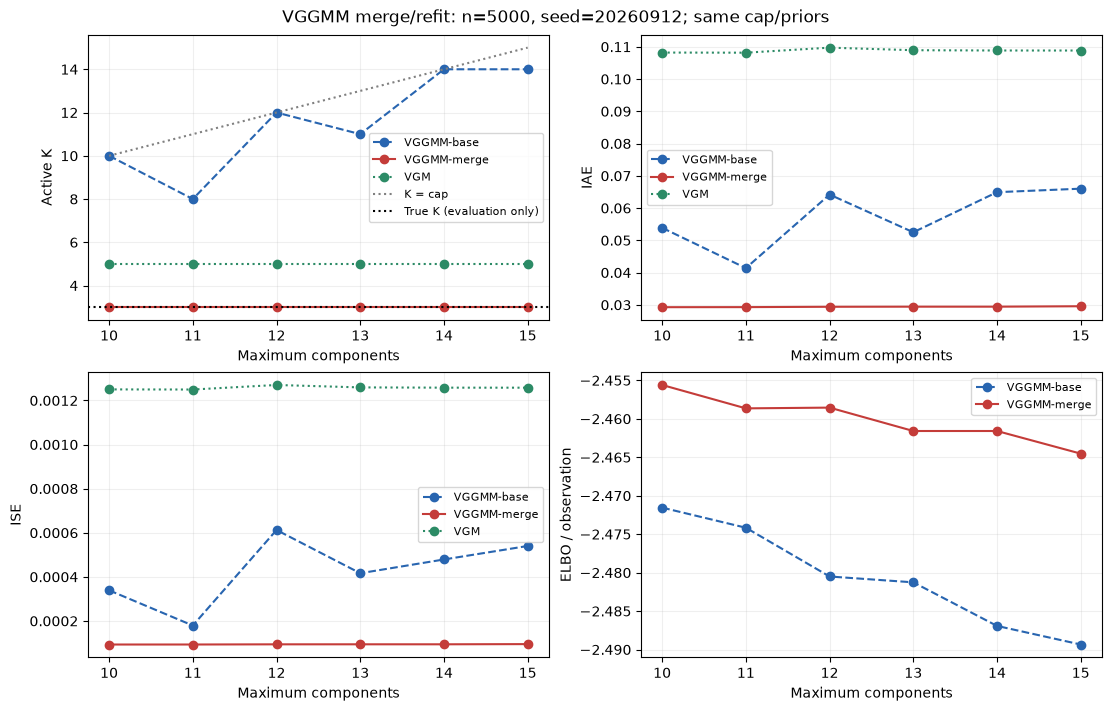

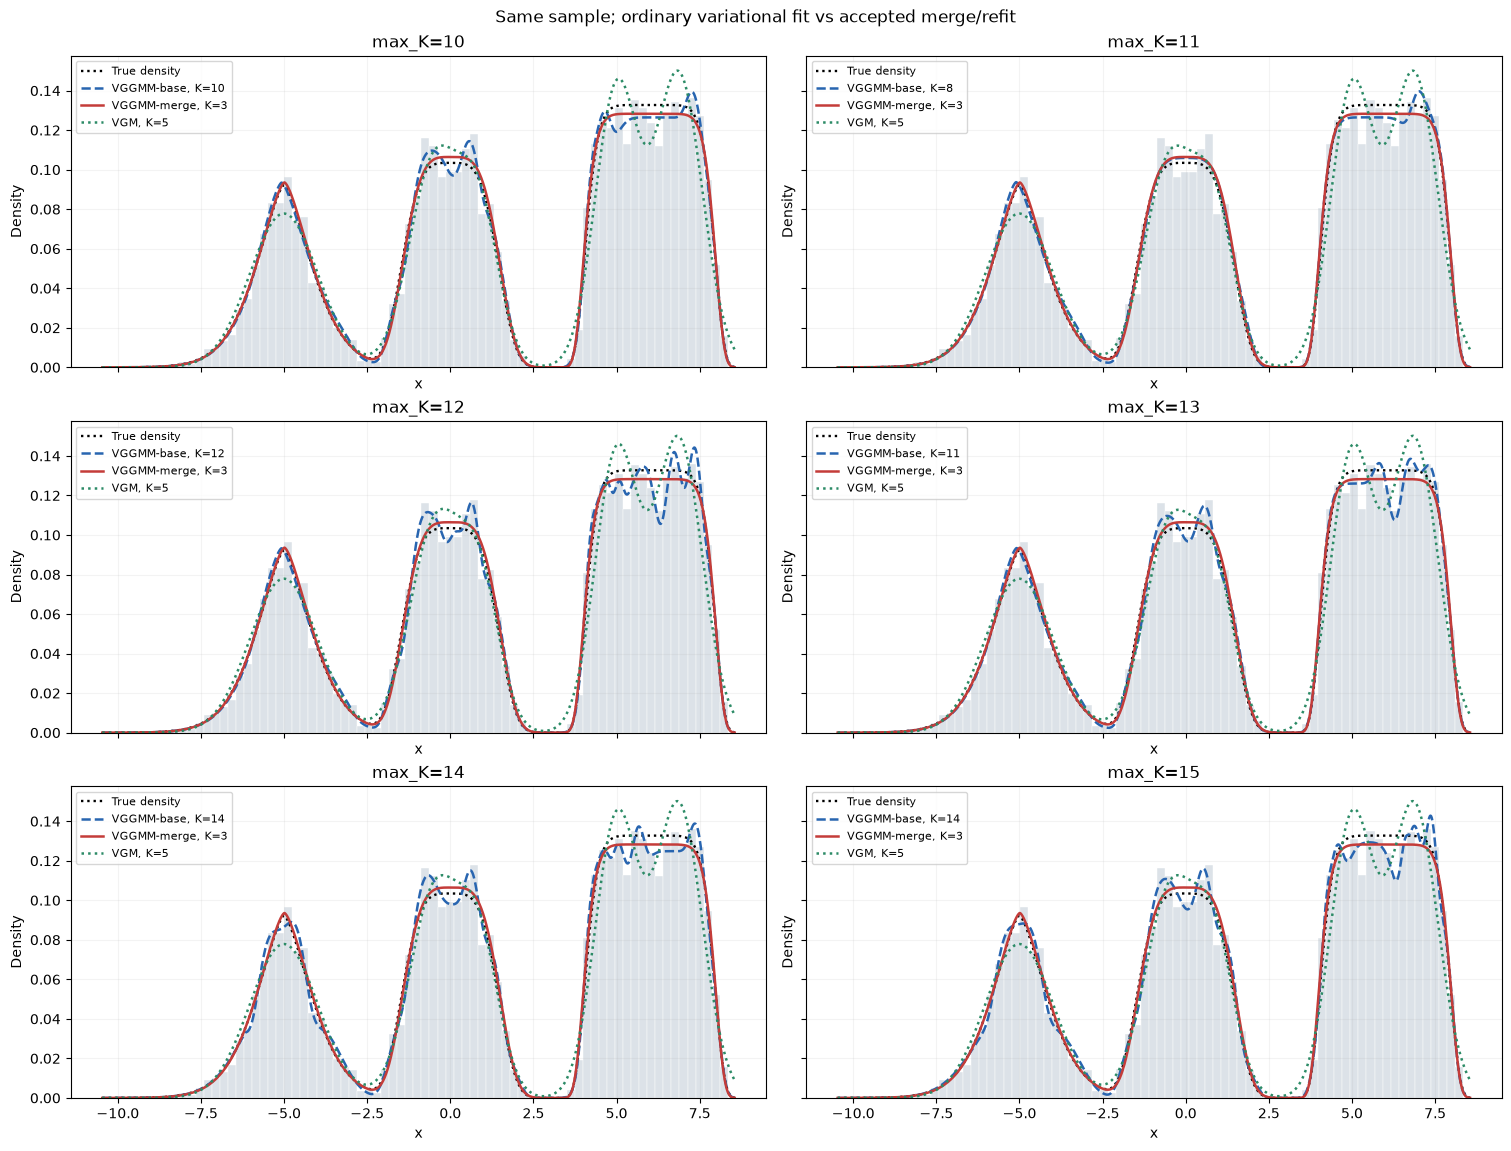

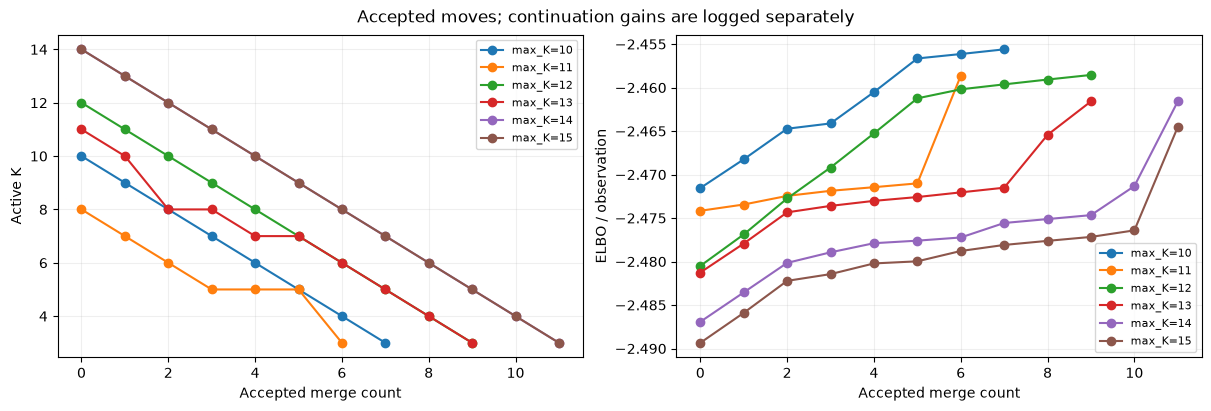

전체 ELBO로 병합을 채택합니다. Active_K·IAE·ISE·참 K는 채택 기준이 아닙니다.


In [22]:
from pathlib import Path
import matplotlib as mpl

export_dir = Path("figures")
export_dir.mkdir(exist_ok=True)

with mpl.rc_context({"svg.fonttype": "path"}):
    # Word용 벡터 그림
    fig.savefig(
        export_dir / "density_comparison.svg",
        bbox_inches="tight", facecolor="white"
    )

    # SVG 삽입이 어려운 경우 사용할 고해상도 그림
    fig.savefig(
        export_dir / "density_comparison.png",
        dpi=600, bbox_inches="tight", facecolor="white"
    )

print("저장 위치:", export_dir.resolve())

styles = {
    "VGGMM-base": ("#2865b0", "--"),
    "VGGMM-merge": ("#c43c39", "-"),
    "VGM": ("#2c8b66", ":"),
}

metrics = tables["metrics"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for method, part in metrics.groupby("Method", sort=False):
    color, style = styles[method]
    for ax, metric in zip(
        axes.flat, ("Active_K", "IAE", "ISE", "ELBO_per_observation")
    ):
        if method == "VGM" and metric == "ELBO_per_observation":
            continue
        ax.plot(
            part.Max_K, part[metric],
            marker="o", color=color, ls=style, label=method,
        )

axes[0, 0].plot(caps, caps, ":", color="gray", label="K = cap")
axes[0, 0].axhline(
    truth.k, color="black", ls=":", label="True K (evaluation only)"
)
for ax, metric in zip(
    axes.flat, ("Active K", "IAE", "ISE", "ELBO / observation")
):
    ax.set(xlabel="Maximum components", ylabel=metric, xticks=caps)
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)

fig.suptitle(
    f"VGGMM merge/refit: n={N}, seed={SAMPLE_SEED}; same cap/priors"
)
fig.savefig(OUTPUT_DIR / "cap_comparison.png", dpi=180)
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

ncols, nrows = min(2, len(caps)), int(np.ceil(len(caps)/2))
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 3.8*nrows),
    squeeze=False, sharex=True, sharey=True,
    layout="constrained",
)
grid_lo = gennorm.ppf(
    1e-5, truth.shapes, loc=truth.means, scale=truth.scales
).min()
grid_hi = gennorm.ppf(
    1-1e-5, truth.shapes, loc=truth.means, scale=truth.scales
).max()
grid = np.linspace(
    min(grid_lo, X.min()), max(grid_hi, X.max()), 2200
)

for ax, cap in zip(axes.flat, caps):
    ax.hist(
        X, bins=70, density=True,
        color="#dce2e8", edgecolor="white", linewidth=.3,
    )
    ax.plot(grid, truth.pdf(grid), "k:", lw=1.7, label="True density")

    for rec in records:
        if rec["cap"] == cap:
            color, style = styles[rec["method"]]
            ax.plot(
                grid, rec["active"].pdf(grid),
                color=color, ls=style, lw=1.8,
                label=f"{rec['method']}, K={rec['active'].k}",
            )

    ax.set(title=f"max_K={cap}", xlabel="x", ylabel="Density")
    ax.legend(fontsize=8)
    ax.grid(alpha=.15)

for ax in list(axes.flat)[len(caps):]:
    ax.set_visible(False)

fig.suptitle(
    "Same sample; ordinary variational fit vs accepted merge/refit"
)
fig.savefig(OUTPUT_DIR / "density_comparison.png", dpi=600)
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for cap in caps:
    model = models[cap]
    accepted = [model.baseline_run_] + model.merge_checkpoints_[1:]

    axes[0].plot(
        range(len(accepted)),
        [model._active_k(run["state"]) for run in accepted],
        "o-", label=f"max_K={cap}",
    )
    axes[1].plot(
        range(len(accepted)),
        [run["elbo"]/N for run in accepted],
        "o-", label=f"max_K={cap}",
    )

for ax, metric in zip(axes, ("Active K", "ELBO / observation")):
    ax.set(xlabel="Accepted merge count", ylabel=metric)
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)

fig.suptitle(
    "Accepted moves; continuation gains are logged separately"
)
fig.savefig(OUTPUT_DIR / "accepted_moves.png", dpi=180)
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

print("전체 ELBO로 병합을 채택합니다. Active_K·IAE·ISE·참 K는 채택 기준이 아닙니다.")


max_K=3: baseline + merge (shape2)
  VGGMM-base: Active_K=3, ELBO/n=-3.0758480, IAE=0.3244029, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-3.0758453, IAE=0.3244362, merges=0

max_K=10: baseline + merge (shape2)
    merge (8, 9): K 9->8, ELBO/n +0.0035886
    merge (7, 8): K 8->7, ELBO/n +0.00329106
    merge (5, 6): K 7->6, ELBO/n +0.00135774
    merge (1, 2): K 6->5, ELBO/n +0.000459632
    merge (3, 4): K 5->5, ELBO/n +0.000394595
  VGGMM-base: Active_K=10, ELBO/n=-2.9760581, IAE=0.0490762, merges=0
  VGGMM-merge: Active_K=5, ELBO/n=-2.9668932, IAE=0.0437616, merges=5


,Method,Max_K,True_K,Active_K,Full_slots,At_cap,IAE,ISE,Converged,Inner_nonconverged,Accepted_merges,Quadrature_OK,Fit_s
0,VGGMM-base,3,5,3,3,True,0.324403,0.007856,True,0,0,True,4.334966
1,VGGMM-merge,3,5,3,3,True,0.324436,0.007855,True,0,0,True,5.313237
2,VGGMM-base,10,5,10,10,True,0.049076,0.000174,True,0,0,True,14.271067
3,VGGMM-merge,10,5,5,10,False,0.043762,0.000131,True,0,5,True,23.951792


,Max_K,Base_active_K,Merge_active_K,Base_IAE,Merge_IAE,Base_ISE,Merge_ISE,Total_delta_ELBO_per_observation,Accepted_merge_ELBO_gain_per_observation,Continuation_ELBO_gain_per_observation,Accepted_merges,Merge_stop_reason,BaseFit_s,MergeExtra_s,TotalFit_s
0,3,3,3,0.324403,0.324436,0.007856,0.007855,0.000003,0.000000,0.000003,0,no_improvement_in_all_prepared_adjacent_pairs,4.334966,0.978203,5.313237
1,10,10,5,0.049076,0.043762,0.000174,0.000131,0.009165,0.009092,0.000073,5,candidate_budget_exhausted_without_improvement,14.271067,9.680652,23.951792


,Method,Max_K,Baseline_fit_s,Merge_extra_s,Finalization_s,Total_fit_s,Continuation_s,Pair_pool_s,Seed_screening_s,Candidate_refit_s,Merge_management_s,Initial_starts_attempted,Continuation_refits,Candidate_seeds,Candidate_refits,Accepted_merges,Evaluation_s
0,VGGMM-base+merge,3,4.334966,0.978203,0.000068,5.313237,0.067372,0.000066,0.322921,0.587748,0.000096,2,1,2,2,0,0.051896
1,VGGMM-base+merge,10,14.271067,9.680652,0.000074,23.951792,1.979166,0.000742,3.671913,4.026630,0.002201,2,6,39,8,5,0.084460


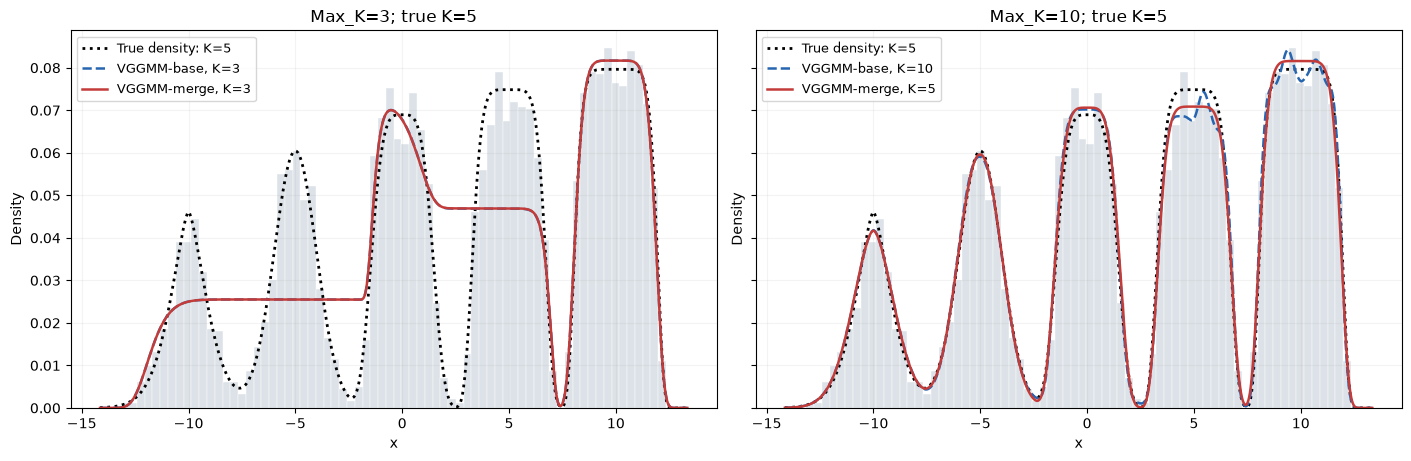

저장 위치: results/max_k_below_true_k/20261012T054145_925395Z
Max_K=3은 최대 3개 슬롯만 사용하며 새 슬롯을 생성하지 않습니다.
수렴 여부와 밀도 적합의 정확성은 별도로 판단합니다.


In [9]:
# max_K < true_K 인 경우에 VGGMM_Merge_Refit이 잘 동작하나 실험
required = ("Mixture", "VGGMMConfig", "run_cap", "combined_tables", "show_table")
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "먼저 모델과 평가 함수 정의 셀을 실행하세요: " + ", ".join(missing)
    )

capacity_n = 5000
capacity_seed = 20260912
capacity_caps = (3, 10)  # true K=5보다 작은 상한과 충분한 상한을 비교합니다.

capacity_truth = Mixture(
    weights=[.10, .15, .20, .25, .30],
    means=[-10., -5., 0., 5., 10.],
    scales=[1.2, 1.4, 1.6, 1.8, 2.0],
    shapes=[1.5, 2., 4., 6., 8.],
)

capacity_rng = np.random.default_rng(capacity_seed)
capacity_labels = capacity_rng.choice(
    capacity_truth.k, size=capacity_n, p=capacity_truth.weights
)
capacity_x = np.asarray(gennorm.rvs(
    capacity_truth.shapes[capacity_labels],
    loc=capacity_truth.means[capacity_labels],
    scale=capacity_truth.scales[capacity_labels],
    random_state=capacity_rng,
), dtype=float)
capacity_x.setflags(write=False)

# 두 조건의 초기화·사전분포·최적화 설정은 같고 Max_K만 다릅니다.
capacity_cfg = VGGMMConfig(
    initial_shape_mode="shape2",
    enable_merge=True,
)
capacity_output = Path("results/max_k_below_true_k") / datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")
capacity_output.mkdir(parents=True, exist_ok=False)

capacity_models, capacity_runs, capacity_records = {}, [], []
for capacity_cap in capacity_caps:
    capacity_model, capacity_one, capacity_rec = run_cap(
        capacity_x, capacity_cap, capacity_cfg, capacity_truth,
        capacity_output, include_vgm=False,
    )
    assert capacity_model.full_k_ == capacity_cap
    assert capacity_model.n_components_ <= capacity_cap

    capacity_models[capacity_cap] = capacity_model
    capacity_runs.append((capacity_cap, capacity_one))
    capacity_records.extend(capacity_rec)

capacity_tables = combined_tables(capacity_runs)
capacity_metrics = capacity_tables["metrics"].copy()
capacity_metrics.insert(2, "True_K", capacity_truth.k)
capacity_metrics["Cap_below_true_K"] = (
    capacity_metrics["Max_K"] < capacity_truth.k
)
capacity_metrics["At_cap"] = (
    capacity_metrics["Active_K"] == capacity_metrics["Full_slots"]
)
capacity_tables["metrics"] = capacity_metrics

for capacity_name, capacity_table in capacity_tables.items():
    capacity_table.to_csv(
        capacity_output / f"{capacity_name}.csv", index=False
    )

show_table(capacity_metrics[[
    "Method", "Max_K", "True_K", "Active_K", "Full_slots", "At_cap",
    "IAE", "ISE", "Converged", "Inner_nonconverged", "Accepted_merges",
    "Quadrature_OK", "Fit_s",
]])
show_table(capacity_tables["paired"])
show_table(capacity_tables["timing"])

capacity_grid = np.linspace(
    capacity_x.min()-1., capacity_x.max()+1., 2400
)
capacity_bins = np.histogram_bin_edges(capacity_x, bins=70)
capacity_fig, capacity_axes = plt.subplots(
    1, 2, figsize=(14, 4.5),
    sharex=True, sharey=True, layout="constrained",
)

for capacity_ax, capacity_cap in zip(capacity_axes, capacity_caps):
    capacity_ax.hist(
        capacity_x, bins=capacity_bins, density=True,
        color="#dce2e8", edgecolor="white", linewidth=.3,
    )
    capacity_ax.plot(
        capacity_grid, capacity_truth.pdf(capacity_grid),
        "k:", lw=2, label="True density: K=5",
    )

    for capacity_rec in capacity_records:
        if capacity_rec["cap"] == capacity_cap:
            capacity_color, capacity_style = (
                ("#2865b0", "--")
                if capacity_rec["method"] == "VGGMM-base"
                else ("#c43c39", "-")
            )
            capacity_ax.plot(
                capacity_grid,
                capacity_rec["active"].pdf(capacity_grid),
                color=capacity_color, ls=capacity_style, lw=1.8,
                label=(
                    f"{capacity_rec['method']}, "
                    f"K={capacity_rec['active'].k}"
                ),
            )

    capacity_ax.set(
        title=f"Max_K={capacity_cap}; true K=5",
        xlabel="x", ylabel="Density",
    )
    capacity_ax.legend(fontsize=9)
    capacity_ax.grid(alpha=.15)

capacity_fig.savefig(
    capacity_output / "density_comparison.png", dpi=180
)
plt.show()
plt.close(capacity_fig)

np.savez_compressed(capacity_output / "sample.npz", X=capacity_x)
capacity_metadata = dict(
    n=capacity_n,
    seed=capacity_seed,
    truth=capacity_truth.payload(),
    caps=capacity_caps,
    config=asdict(capacity_cfg),
    sample_sha256=hashlib.sha256(
        np.asarray(capacity_x, dtype="<f8").tobytes()
    ).hexdigest(),
    fitting_uses_truth=False,
    shape_is_free=True,
)
(capacity_output / "metadata.json").write_text(
    json.dumps(capacity_metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("저장 위치:", capacity_output)
print("Max_K=3은 최대 3개 슬롯만 사용하며 새 슬롯을 생성하지 않습니다.")
print("수렴 여부와 밀도 적합의 정확성은 별도로 판단합니다.")

In [10]:
"""Density errors for a generic reference density and a fitted GGD mixture.

The reference supplies pdf(x), cdf(x), evaluation_points(tail) and peak_upper().
It can contain Gaussian, Student t, skew-normal or other component families.
The fitted object supplies pdf/cdf and GGD weights, means, scales and shapes.
Truth is used by this evaluation helper only, never by variational fitting.
"""

import numpy as np
from scipy.special import gammaln
from scipy.stats import gennorm


def _legendre_rule(order):
    # NumPy's Gauss-Legendre rule is exact for polynomials of degree 2*order-1.
    return np.polynomial.legendre.leggauss(order)


_LEGENDRE = {order: _legendre_rule(order) for order in (32, 64)}


def _ggd_points(fitted, tail):
    probabilities = np.unique(np.array([
        tail, 1e-6, 1e-4, .001, .01, .1, .25, .5,
        .75, .9, .99, .999, 1-1e-4, 1-1e-6, 1-tail,
    ]))
    return gennorm.ppf(probabilities[:, None], np.asarray(fitted.shapes),
                       loc=np.asarray(fitted.means), scale=np.asarray(fitted.scales)).ravel()


def _ggd_peak_upper(fitted):
    # Each GGD attains its maximum at its location. The weighted sum of
    # component maxima bounds the entire mixture, even with distinct locations.
    weights = np.asarray(fitted.weights)
    log_peaks = (-np.log(2.)-np.log(np.asarray(fitted.scales))
                 -gammaln(1+1/np.asarray(fitted.shapes)))
    return float(np.sum(weights*np.exp(log_peaks)))


def _omitted_mass(model, left, right):
    values = np.asarray(model.cdf(np.array([left, right])), dtype=float).reshape(-1)
    if values.shape != (2,) or not np.isfinite(values).all():
        raise FloatingPointError("Density evaluation needs two finite CDF values.")
    if np.any(values < -1e-12) or np.any(values > 1+1e-12) or values[1] < values[0]-1e-12:
        raise ValueError("Density evaluation received invalid CDF values.")
    return float(np.clip(values[0]+(1-values[1]), 0., 1.))


def density_errors(truth, fitted, tail=1e-9, atol=1e-7, rtol=1e-5, max_refinement=16):
    """Estimate IAE/ISE adaptively, and bound error omitted outside the interval.

    IAE = integral |fitted(x)-truth(x)| dx.
    ISE = integral (fitted(x)-truth(x))**2 dx.
    ``*_quad_error`` estimates numerical error using 32/64-point rule differences;
    it is not a rigorous quadrature bound. ``*_tail_upper`` bounds the omitted
    tails if truth.peak_upper() is a valid global density upper bound.
    Quadrature_OK checks rule agreement and refinement completion only.
    It does not assert model normalization or statistical goodness of fit.
    """
    if (not np.isfinite(tail) or not 0 < tail < .5
        or not np.isfinite(atol) or atol <= 0
        or not np.isfinite(rtol) or rtol < 0
        or not isinstance(max_refinement, (int, np.integer))
        or isinstance(max_refinement, (bool, np.bool_)) or max_refinement < 0):
        raise ValueError("Invalid density-error quadrature settings.")
    reference_points = np.asarray(truth.evaluation_points(tail), dtype=float).ravel()
    points = np.unique(np.r_[reference_points, _ggd_points(fitted, tail)])
    if len(points) < 2 or not np.isfinite(points).all():
        raise FloatingPointError("Evaluation quantiles cannot be represented as a finite interval.")
    truth_peak, fitted_peak = float(truth.peak_upper()), _ggd_peak_upper(fitted)
    if (not np.isfinite(truth_peak) or truth_peak < 0
        or not np.isfinite(fitted_peak) or fitted_peak < 0):
        raise FloatingPointError("Density tail bounds require finite nonnegative peak bounds.")

    left, right = points[:-1], points[1:]
    n_panels = len(left)
    depth = np.zeros(n_panels, dtype=int)
    total, error = np.zeros(2), np.zeros(2)
    unresolved = 0

    def panel(l, r, order):
        nodes, weights = _LEGENDRE[order]
        mid, half = l/2+r/2, (r-l)/2
        xx = mid[:, None]+half[:, None]*nodes
        fitted_pdf = np.asarray(fitted.pdf(xx.ravel()), dtype=float).reshape(xx.shape)
        true_pdf = np.asarray(truth.pdf(xx.ravel()), dtype=float).reshape(xx.shape)
        if not np.isfinite(fitted_pdf).all() or not np.isfinite(true_pdf).all():
            raise FloatingPointError("Nonfinite density value during quadrature.")
        delta = fitted_pdf-true_pdf
        return np.c_[np.abs(delta)@weights, delta**2@weights]*half[:, None]

    while len(left):
        low, high = panel(left, right, 32), panel(left, right, 64)
        difference = np.abs(high-low)
        good = np.all(difference <= atol/n_panels/(2.**depth[:, None])+rtol*np.abs(high), axis=1)
        stopped = depth >= max_refinement
        accept = good | stopped
        total += high[accept].sum(axis=0)
        error += difference[accept].sum(axis=0)
        unresolved += int(np.sum(stopped & ~good))
        ll, rr, dd = left[~accept], right[~accept], depth[~accept]
        mid = ll/2+rr/2
        left, right, depth = np.r_[ll, mid], np.r_[mid, rr], np.r_[dd+1, dd+1]

    lo, hi = float(points[0]), float(points[-1])
    true_tail, fitted_tail = _omitted_mass(truth, lo, hi), _omitted_mass(fitted, lo, hi)
    return dict(IAE=float(total[0]), ISE=float(total[1]),
        IAE_quad_error=float(error[0]), ISE_quad_error=float(error[1]),
        IAE_tail_upper=true_tail+fitted_tail,
        ISE_tail_upper=truth_peak*true_tail+fitted_peak*fitted_tail,
        Quadrature_OK=bool(unresolved == 0 and np.all(error <= atol+rtol*np.abs(total))),
        Evaluation_left=lo, Evaluation_right=hi, Unresolved_panels=unresolved)

"""Portable experiments; the estimator itself is imported from its .py file."""

from dataclasses import asdict
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.util
import json
import platform
import sys
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm, laplace, t, skewnorm
from sklearn.mixture import BayesianGaussianMixture
from threadpoolctl import threadpool_limits


cwd = Path.cwd().resolve()
MODEL_FILE = next((p for folder in (cwd, *cwd.parents)
                   for p in (folder / "vggmm_merge_refit.py",
                             folder / "GGMM" / "vggmm_merge_refit.py")
                   if p.is_file()), None)
if MODEL_FILE is None:
    raise FileNotFoundError("모델 .py와 노트북을 같은 폴더에 두고 저장소 폴더를 여세요.")
spec = importlib.util.spec_from_file_location("vggmm_merge_refit", MODEL_FILE)
vg = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = vg
spec.loader.exec_module(vg)
Mixture, VGGMMConfig, VariationalGGMM = vg.Mixture, vg.VGGMMConfig, vg.VariationalGGMM

# These choices are fixed before observing any result. b remains free after b=2 initialization.
SEEDS = (20260912, 20260913, 20260914)
N_TRAIN, N_TEST = 5000, 5000
MAX_K = 10
CONFIG = VGGMMConfig(max_components=MAX_K, initial_shape_mode="shape2", enable_merge=True)
OUTPUT_ROOT = Path("results")
ABALONE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
ABALONE_SOURCE = "https://archive.ics.uci.edu/dataset/1/abalone"
VGM_SETTINGS = dict(n_components=MAX_K, covariance_type="full",
    weight_concentration_prior_type="dirichlet_process",
    weight_concentration_prior=CONFIG.concentration, init_params="kmeans", n_init=2,
    max_iter=1500, tol=1e-3, reg_covar=1e-6, random_state=27)
METHODS = ("VGGMM_base", "VGGMM_merge", "VGM")


class ReferenceMixture:
    """Evaluation/sampling object supporting different SciPy distribution families."""
    def __init__(self, weights, components, peak_bounds, description):
        self.weights = np.array(weights, dtype=float)
        self.components = tuple(components)
        self.peak_bounds = np.array(peak_bounds, dtype=float)
        self.description = description
        if (len(self.weights) != len(self.components) or self.peak_bounds.shape != self.weights.shape
            or np.any(self.weights <= 0) or not np.isclose(self.weights.sum(), 1)):
            raise ValueError("Invalid reference mixture.")

    def logpdf(self, x):
        x = np.asarray(x).reshape(-1)
        return logsumexp(np.column_stack([c.logpdf(x) for c in self.components])
                         + np.log(self.weights), axis=1)

    def pdf(self, x):
        return np.exp(self.logpdf(x))

    def cdf(self, x):
        return np.column_stack([c.cdf(x) for c in self.components]) @ self.weights

    def evaluation_points(self, tail):
        p = np.unique(np.array([tail, 1e-6, 1e-4, .001, .01, .1, .25, .5,
                                .75, .9, .99, .999, 1-1e-4, 1-1e-6, 1-tail]))
        return np.concatenate([c.ppf(p) for c in self.components])

    def peak_upper(self):
        return float(self.weights @ self.peak_bounds)

    def sample(self, n, seed):
        rng = np.random.default_rng(seed)
        labels = rng.choice(len(self.weights), size=n, p=self.weights)
        x = np.empty(n)
        for k, component in enumerate(self.components):
            keep = labels == k
            x[keep] = component.rvs(size=int(keep.sum()), random_state=rng)
        return x


def gaussian_reference():
    # These scales are NORMAL standard deviations, rather than GGD scale a.
    weights, means, sigmas = [.2, .3, .5], [-5., 0., 6.], [1.2, 1.6, 2.]
    return ReferenceMixture(weights, [norm(loc=m, scale=s) for m, s in zip(means, sigmas)],
        [1/(np.sqrt(2*np.pi)*s) for s in sigmas],
        dict(weights=weights, means=means, normal_standard_deviations=sigmas,
             families=["Gaussian"]*3, generating_components=3))


def heterogeneous_reference():
    components = [norm(loc=-7., scale=.9), laplace(loc=-2., scale=.7),
                  t(df=5, loc=4., scale=1.), skewnorm(a=6., loc=9., scale=1.5)]
    return ReferenceMixture([.20, .25, .25, .30], components,
        [1/(.9*np.sqrt(2*np.pi)), 1/(2*.7), components[2].pdf(4.), 2/(1.5*np.sqrt(2*np.pi))],
        dict(weights=[.20, .25, .25, .30], generating_components=4,
             families=["Gaussian", "Laplace", "Student-t", "skew-normal"],
             parameters=[dict(loc=-7., scale=.9), dict(loc=-2., scale=.7),
                         dict(df=5, loc=4., scale=1.), dict(a=6., loc=9., scale=1.5)]))


def synthetic_sample(reference, seed):
    return (reference.sample(N_TRAIN, seed), reference.sample(N_TEST, seed+1000), reference,
            dict(train_seed=seed, test_seed=seed+1000, reference=reference.description))


def load_abalone():
    # Relative path works after cloning the repository on any computer.
    data_file = MODEL_FILE.parent / "data" / "abalone.data"
    if not data_file.is_file():
        data_file.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(ABALONE_URL, timeout=45) as response:
            content = response.read()
        data_file.write_bytes(content)
    columns = ["Sex", "Length", "Diameter", "Height", "Whole_weight", "Shucked_weight",
               "Viscera_weight", "Shell_weight", "Rings"]
    data = pd.read_csv(data_file, header=None, names=columns)
    x = data["Whole_weight"].to_numpy(dtype=float, copy=True)
    if len(data) != 4177 or not np.isfinite(x).all() or np.any(x <= 0):
        raise ValueError("UCI Abalone 원자료의 행 수와 Whole_weight를 확인하세요.")
    return x, dict(dataset="UCI Abalone", column="Whole_weight", rows=len(x),
        units="UCI stored scale (continuous values divided by 200 according to abalone.names)",
        source=ABALONE_SOURCE, raw_url=ABALONE_URL, license="CC BY 4.0",
        data_sha256=hashlib.sha256(data_file.read_bytes()).hexdigest())


def real_sample(x, metadata, seed):
    indices = np.random.default_rng(seed).permutation(len(x))
    cut = int(.8*len(x))
    return x[indices[:cut]], x[indices[cut:]], None, dict(**metadata, split_seed=seed,
        split="80/20 shuffled holdout", train_indices=indices[:cut].tolist(),
        test_indices=indices[cut:].tolist(), nonnegative_support=True)


def fit_vgm(x):
    estimator = BayesianGaussianMixture(**VGM_SETTINGS)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        begin = perf_counter()
        estimator.fit(x.reshape(-1, 1).copy())
        fit_seconds = perf_counter()-begin
    # A common output convention: normalized posterior-parameter plug-in density.
    # Gaussian SD sigma corresponds to GGD a=sqrt(2)*sigma at b=2.
    density = Mixture(estimator.weights_/estimator.weights_.sum(), estimator.means_[:, 0],
        np.sqrt(2*estimator.covariances_[:, 0, 0]), np.full(MAX_K, 2.))
    return density, dict(Fit_s=fit_seconds, Baseline_fit_s=fit_seconds, Merge_extra_s=0.,
        Converged=bool(estimator.converged_), Iterations=int(estimator.n_iter_),
        Stop_reason="tolerance" if estimator.converged_ else "iteration_limit",
        Inner_nonconverged=np.nan, Failed_starts=0, Accepted_merges=0,
        Chosen_start="kmeans", ELBO_gain_per_obs=np.nan,
        Warning_count=len(caught), Warnings=[str(w.message) for w in caught])


def evaluate_density(density, x_train, x_test, truth, nonnegative):
    begin = perf_counter()
    full = dict(Train_LL_per_obs=float(np.mean(density.logpdf(x_train))),
                Test_LL_per_obs=float(np.mean(density.logpdf(x_test))),
                Negative_mass=float(density.cdf([0.])[0]) if nonnegative else np.nan)
    if truth is not None:
        full.update(density_errors(truth, density))
    keep = density.weights > CONFIG.active_threshold
    retained = float(density.weights[keep].sum())
    full.update(Active_K=int(keep.sum()), Excluded_mass=float(density.weights[~keep].sum()))
    if keep.any():
        active = Mixture(density.weights[keep]/retained, density.means[keep],
                         density.scales[keep], density.shapes[keep])
        full["Active_Test_LL_per_obs"] = float(np.mean(active.logpdf(x_test)))
        if truth is not None:
            err = density_errors(truth, active)
            full.update({"Active_"+k: err[k] for k in ("IAE", "ISE", "Quadrature_OK")})
    full["Evaluation_s"] = perf_counter()-begin
    if not np.isfinite(full["Test_LL_per_obs"]):
        raise FloatingPointError("Test log density is nonfinite.")
    return full


def json_value(x):
    if isinstance(x, (np.integer, np.floating, np.bool_)):
        return x.item()
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, Path):
        return str(x)
    raise TypeError(type(x).__name__)


def run_study(study_id, sample_factory, *, seeds=SEEDS):
    """All fits use X_train only; truth and test data enter subsequent evaluation."""
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    output = OUTPUT_ROOT / study_id / run_id
    output.mkdir(parents=True, exist_ok=False)
    rows, cases, arrays, log_rows, timing_rows = [], [], {}, [], []
    study_begin = perf_counter()
    actual_fit_s = 0.
    for seed in seeds:
        x_train, x_test, truth, metadata = sample_factory(seed)
        x_train = np.array(x_train, dtype=float, copy=True)
        x_test = np.array(x_test, dtype=float, copy=True)
        original = x_train.copy()
        prefix = f"seed_{seed}"
        arrays[prefix+"_train"], arrays[prefix+"_test"] = x_train, x_test
        case = dict(seed=int(seed), metadata=metadata, truth=truth, x_train=x_train,
                    densities={}, diagnostics={})
        fitted = {}
        print(f"{study_id}: seed={seed}, train={len(x_train)}, test={len(x_test)}, Max_K={MAX_K}", flush=True)
        begin = perf_counter()
        vggmm_time_recorded = False
        try:
            with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model = VariationalGGMM(CONFIG).fit(x_train)
            actual_fit_s += model.fit_seconds_
            vggmm_time_recorded = True
            case["diagnostics"] = dict(timing=model.timing_, work=model.work_,
                initial_start_timing=model.initial_start_timing_, failed_starts=model.failed_starts_,
                warnings=[str(w.message) for w in caught],
                baseline_selection_fallback=model.baseline_selection_fallback_,
                merge_stop_reason=model.merge_stop_reason_)
            final_r = model.posterior_state_["r"]
            if final_r.shape != (len(x_train), MAX_K) or not np.allclose(final_r.sum(axis=1), 1., atol=1e-10):
                raise AssertionError("Responsibility rows or capacity are inconsistent.")
            if model.final_run_["elbo"] < model.baseline_run_["elbo"]-1e-7:
                raise AssertionError("Accepted search reduced the full ELBO.")
            if not np.isclose(model.timing_["Baseline_fit_s"]+model.timing_["Merge_extra_s"]
                              +model.timing_["Finalization_s"], model.fit_seconds_, atol=1e-9):
                raise AssertionError("Fit time accounting is inconsistent.")
            for name, state in (("baseline", model.baseline_run_["state"]),
                                ("final", model.posterior_state_)):
                for key, value in state.items():
                    arrays[prefix+"_"+name+"_"+key] = value
            for phase, entries in (("merge", model.merge_log_), ("continuation", model.continuation_log_),
                                   ("seed_screening", model.seed_log_)):
                for entry in entries:
                    log_rows.append(dict(Seed=seed, Phase=phase, **entry))
            timing_rows.append(dict(Seed=seed, **model.timing_, **model.work_))
            for method, density, run in (("VGGMM_base", model.baseline_density_, model.baseline_run_),
                                          ("VGGMM_merge", model.full_density_, model.final_run_)):
                merged = method == "VGGMM_merge"
                info = dict(Fit_s=model.fit_seconds_ if merged else model.baseline_seconds_,
                    Baseline_fit_s=model.baseline_seconds_, Merge_extra_s=model.merge_seconds_ if merged else 0.,
                    Converged=bool(run["converged"]), Iterations=len(run["history"])-1,
                    Stop_reason=run["reason"], Inner_nonconverged=run["inner_nonconverged"],
                    Failed_starts=len(model.failed_starts_), Warning_count=len(caught),
                    Chosen_start=model.baseline_run_["name"], Accepted_merges=model.accepted_merges_ if merged else 0,
                    ELBO_gain_per_obs=(run["elbo"]-model.baseline_run_["elbo"])/len(x_train))
                fitted[method] = (density, info)
        except Exception as exc:
            if not vggmm_time_recorded:
                actual_fit_s += perf_counter()-begin
            case["diagnostics"]["vggmm_error"] = f"{type(exc).__name__}: {exc}"
        begin = perf_counter()
        try:
            with threadpool_limits(limits=1):
                density, info = fit_vgm(x_train)
            actual_fit_s += info["Fit_s"]
            fitted["VGM"] = (density, info)
        except Exception as exc:
            actual_fit_s += perf_counter()-begin
            case["diagnostics"]["vgm_error"] = f"{type(exc).__name__}: {exc}"
        if not np.array_equal(x_train, original):
            raise AssertionError("A fitter modified the input sample.")
        for method in METHODS:
            row = dict(Study=study_id, Seed=seed, Method=method, Max_K=MAX_K,
                       Train_N=len(x_train), Test_N=len(x_test), Status="fit_failed")
            if method in fitted:
                density, info = fitted[method]
                case["densities"][method] = density
                for key, value in density.payload().items():
                    arrays[prefix+"_"+method+"_"+key] = np.asarray(value)
                row.update(info, Status="ok")
                try:
                    row.update(evaluate_density(density, x_train, x_test, truth,
                                                metadata.get("nonnegative_support", False)))
                except Exception as exc:
                    row.update(Status="evaluation_failed", Evaluation_error=f"{type(exc).__name__}: {exc}")
            else:
                row["Fit_error"] = case["diagnostics"].get("vgm_error" if method == "VGM" else "vggmm_error", "")
            rows.append(row)
        cases.append(case)
        print(" | ".join(f"{r['Method']}: K={r.get('Active_K', '?')}, "
            f"test LL={r.get('Test_LL_per_obs', np.nan):.6f}, {r.get('Fit_s', np.nan):.2f}s, "
            f"converged={r.get('Converged', False)}" for r in rows[-3:]), flush=True)
        # Save each completed seed, so interruption cannot discard completed fits.
        pd.DataFrame(rows).to_csv(output / "metrics.csv", index=False)
        np.savez_compressed(output / "samples_and_states.npz", **arrays)
    table = pd.DataFrame(rows)
    pd.DataFrame(log_rows).to_csv(output / "search_log.csv", index=False)
    pd.DataFrame(timing_rows).to_csv(output / "timing.csv", index=False)
    metadata_out = dict(study_id=study_id, seeds=list(seeds), config=asdict(CONFIG),
        vgm_settings=VGM_SETTINGS, density_kind="full posterior-parameter plug-in density",
        primary_metrics="heldout mean log density; synthetic IAE/ISE",
        versions=dict(python=platform.python_version(), **{p:version(p) for p in
            ("numpy", "scipy", "pandas", "matplotlib", "scikit-learn")}),
        model_sha256=hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest(),
        actual_fit_s=actual_fit_s, fit_evaluate_save_wall_s=perf_counter()-study_begin,
        cases=[dict(seed=c["seed"], metadata=c["metadata"], diagnostics=c["diagnostics"]) for c in cases])
    (output / "metadata.json").write_text(json.dumps(metadata_out, ensure_ascii=False,
        indent=2, default=json_value), encoding="utf-8")
    study = dict(table=table, cases=cases, output=output, metadata=metadata_out)
    study["paired"] = paired_comparisons(study)
    study["paired"].to_csv(output / "paired_differences.csv", index=False)
    summary = summarize_pairs(study["paired"])
    summary.to_csv(output / "paired_summary.csv", index=False)
    study["paired_summary"] = summary
    show_study(study)
    metadata_out["total_study_wall_s"] = perf_counter()-study_begin
    (output / "metadata.json").write_text(json.dumps(metadata_out, ensure_ascii=False,
        indent=2, default=json_value), encoding="utf-8")
    return study


def paired_comparisons(study):
    rows, table = [], study["table"]
    metrics = [m for m in ("IAE", "ISE", "Test_LL_per_obs", "Fit_s") if m in table]
    for seed in sorted(table["Seed"].unique()):
        group = table[table["Seed"] == seed].set_index("Method")
        for left, right in (("VGGMM_merge", "VGM"), ("VGGMM_merge", "VGGMM_base")):
            a, b = group.loc[left], group.loc[right]
            evaluated = a["Status"] == b["Status"] == "ok"
            converged = lambda row: pd.notna(row.get("Converged")) and bool(row.get("Converged"))
            row = dict(Study=a["Study"], Seed=seed, Comparison=left+" minus "+right,
                       Both_evaluated=evaluated,
                       Both_converged=bool(evaluated and converged(a) and converged(b)))
            for metric in metrics:
                row["Delta_"+metric] = a.get(metric, np.nan)-b.get(metric, np.nan)
            rows.append(row)
    return pd.DataFrame(rows)


def summarize_pairs(paired):
    rows = []
    for comparison, group in paired.groupby("Comparison", sort=False):
        for metric in [c for c in paired if c.startswith("Delta_")]:
            values = group[metric].dropna().to_numpy()
            lower_is_better = metric != "Delta_Test_LL_per_obs"
            signs = -values if lower_is_better else values
            rows.append(dict(Comparison=comparison, Metric=metric, Valid_seeds=len(values),
                Total_seeds=len(group), Both_converged_seeds=int(group["Both_converged"].sum()),
                Mean_delta=float(values.mean()) if len(values) else np.nan,
                SD_delta=float(values.std(ddof=1)) if len(values)>1 else np.nan,
                Left_wins=int(np.sum(signs>1e-10)), Right_wins=int(np.sum(signs< -1e-10)),
                Ties=int(np.sum(np.abs(signs)<=1e-10))))
    return pd.DataFrame(rows)


def show_study(study):
    table = study["table"]
    columns = [c for c in ("Seed", "Method", "Active_K", "IAE", "ISE", "Test_LL_per_obs",
        "Negative_mass", "Fit_s", "Merge_extra_s", "Converged", "Accepted_merges",
        "Inner_nonconverged", "Failed_starts", "Quadrature_OK", "Status") if c in table]
    try:
        from IPython.display import display
        display(table[columns], study["paired_summary"])
    except ImportError:
        print(table[columns].to_string(index=False))
        print(study["paired_summary"].to_string(index=False))
    fig, axes = plt.subplots(1, len(study["cases"]), figsize=(5*len(study["cases"]), 3.8),
                             squeeze=False, layout="constrained")
    styles = {"VGGMM_base":("#777777", "--"), "VGGMM_merge":("#c43c39", "-"), "VGM":("#2865b0", "-.")}
    for ax, case in zip(axes[0], study["cases"]):
        x = case["x_train"]
        truth = case["truth"]
        densities = case["densities"]
        lo, hi = np.quantile(x, [.001, .999])
        pad = .1*(hi-lo)
        grid = np.linspace(lo-pad, hi+pad, 2400)
        ax.hist(x, bins=65, density=True, color="#dce2e8", edgecolor="white", linewidth=.3)
        if truth is not None:
            ax.plot(grid, truth.pdf(grid), "k:", lw=2., label="Truth")
        for method, density in densities.items():
            color, style = styles[method]
            k = int(np.sum(density.weights > CONFIG.active_threshold))
            ax.plot(grid, density.pdf(grid), color=color, ls=style, lw=1.7,
                    label=f"{method}, active K={k}")
        xlabel = "Whole_weight (UCI stored scale)" if truth is None else "x"
        ax.set(title=f"seed={case['seed']}", xlabel=xlabel, ylabel="Density")
        ax.set_ylim(bottom=0.)
        ax.grid(alpha=.15)
        ax.legend(fontsize=8)
    fig.savefig(study["output"] / "density.png", dpi=160)
    plt.show()
    plt.close(fig)
    print("주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.")
    print("Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.")
    print("저장:", study["output"], "| 실제 적합 시간 합:", round(study["metadata"]["actual_fit_s"], 2), "s")


In [15]:
%pip install certifi

import ssl
import certifi
import urllib.request

https_context = ssl.create_default_context(cafile=certifi.where())
urllib.request.install_opener(
    urllib.request.build_opener(
        urllib.request.HTTPSHandler(context=https_context)
    )
)

abalone_x, abalone_metadata = load_abalone()
print(f"Abalone 로딩 성공: {len(abalone_x):,}개 관측값")

Note: you may need to restart the kernel to use updated packages.
Abalone 로딩 성공: 4,177개 관측값


abalone_whole_weight: seed=20260912, train=3341, test=836, Max_K=10
    merge (4, 5): K 10->9, ELBO/n +0.00150179
    merge (2, 3): K 9->8, ELBO/n +0.00138946
    merge (1, 2): K 8->7, ELBO/n +0.000441433
    merge (4, 6): K 7->6, ELBO/n +0.000991929
    merge (8, 9): K 6->5, ELBO/n +0.00319423
    merge (1, 4): K 5->4, ELBO/n +0.000461508
    merge (7, 8): K 4->3, ELBO/n +0.00376649
    merge (1, 7): K 3->2, ELBO/n +0.0138011
VGGMM_base: K=10, test LL=-0.639338, 22.14s, converged=True | VGGMM_merge: K=2, test LL=-0.653161, 41.97s, converged=True | VGM: K=5, test LL=-0.644723, 1.42s, converged=True
abalone_whole_weight: seed=20260913, train=3341, test=836, Max_K=10
    merge (2, 3): K 10->9, ELBO/n +0.00149773
    merge (4, 5): K 9->8, ELBO/n +0.00117616
    merge (1, 2): K 8->7, ELBO/n +0.000880855
    merge (1, 4): K 7->6, ELBO/n +0.00219968
    merge (1, 6): K 6->5, ELBO/n +0.00145008
    merge (7, 8): K 5->4, ELBO/n +0.000661215
    merge (7, 9): K 4->3, ELBO/n +0.00543071
    merg

,Seed,Method,Active_K,Test_LL_per_obs,Negative_mass,Fit_s,Merge_extra_s,Converged,Accepted_merges,Inner_nonconverged,Failed_starts,Status
0,20260912,VGGMM_base,10,-0.639338,0.000617,22.137588,0.000000,True,0,0.0,0,ok
1,20260912,VGGMM_merge,2,-0.653161,0.008662,41.968504,19.830847,True,8,0.0,0,ok
2,20260912,VGM,5,-0.644723,0.006725,1.420912,0.000000,True,0,NaN,0,ok
3,20260913,VGGMM_base,10,-0.631257,0.000517,15.557782,0.000000,True,0,0.0,0,ok
4,20260913,VGGMM_merge,2,-0.638673,0.009127,30.804445,15.246582,True,8,0.0,0,ok
5,20260913,VGM,4,-0.634796,0.007217,2.251698,0.000000,True,0,NaN,0,ok
6,20260914,VGGMM_base,10,-0.634931,0.000630,12.303124,0.000000,True,0,0.0,0,ok
7,20260914,VGGMM_merge,2,-0.637244,0.008918,30.285510,17.982322,True,8,0.0,0,ok
8,20260914,VGM,4,-0.634562,0.007485,1.695776,0.000000,True,0,NaN,0,ok


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties
0,VGGMM_merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.004999,0.003038,0,3,0
1,VGGMM_merge minus VGM,Delta_Fit_s,3,3,3,32.563358,6.914575,0,3,0
2,VGGMM_merge minus VGGMM_base,Delta_Test_LL_per_obs,3,3,3,-0.007851,0.005767,0,3,0
3,VGGMM_merge minus VGGMM_base,Delta_Fit_s,3,3,3,17.686655,2.306390,0,3,0


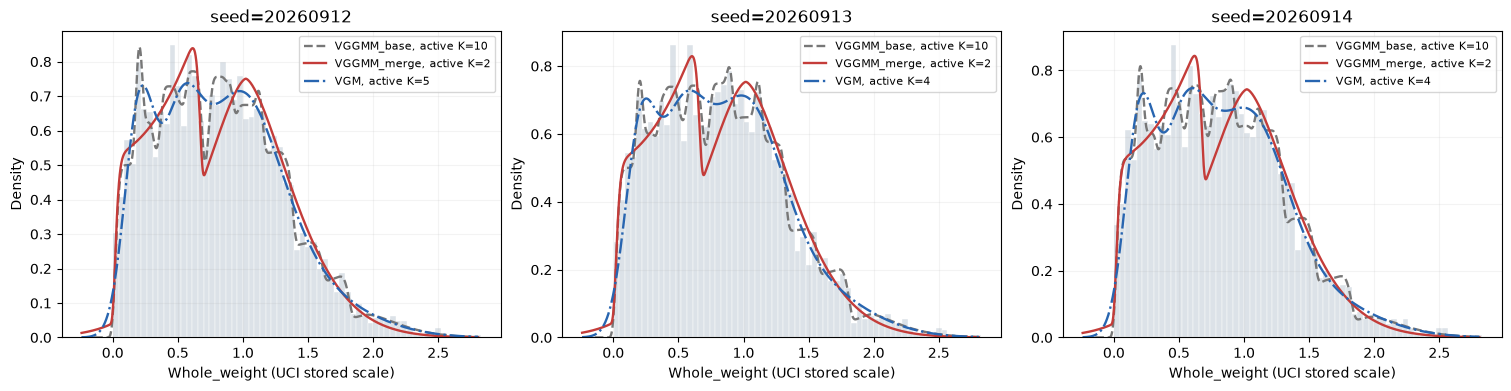

주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.
Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.
저장: results/abalone_whole_weight/20261012T054216_594230Z | 실제 적합 시간 합: 108.43 s


In [11]:
# 실험 2: 실제 공개 자료. 참 밀도/참 K는 알려져 있지 않습니다.
# UCI Abalone (Nash et al., 1994), CC BY 4.0, https://doi.org/10.24432/C55C7W
abalone_x, abalone_metadata = load_abalone()
real_study = run_study("abalone_whole_weight",
    lambda seed: real_sample(abalone_x, abalone_metadata, seed))


gaussian_mixture: seed=20260912, train=5000, test=5000, Max_K=10
    merge (1, 2): K 10->9, ELBO/n +0.000958697
    merge (4, 5): K 9->8, ELBO/n +0.000857078
    merge (7, 8): K 8->7, ELBO/n +0.000941777
    merge (6, 7): K 7->6, ELBO/n +0.000237228
    merge (3, 4): K 6->5, ELBO/n +0.000210002
    merge (6, 9): K 5->4, ELBO/n +0.0060925
    merge (1, 3): K 4->3, ELBO/n +0.00101949
VGGMM_base: K=10, test LL=-2.818847, 39.38s, converged=True | VGGMM_merge: K=3, test LL=-2.816663, 78.20s, converged=True | VGM: K=3, test LL=-2.816363, 2.09s, converged=True
gaussian_mixture: seed=20260913, train=5000, test=5000, Max_K=10
    merge (2, 3): K 10->9, ELBO/n +0.000873293
    merge (7, 8): K 9->8, ELBO/n +0.000252393
VGGMM_base: K=10, test LL=-2.838801, 22.40s, converged=True | VGGMM_merge: K=8, test LL=-2.839521, 45.05s, converged=True | VGM: K=3, test LL=-2.833776, 2.02s, converged=True
gaussian_mixture: seed=20260914, train=5000, test=5000, Max_K=10
    merge (6, 7): K 10->9, ELBO/n +0.00139

,Seed,Method,Active_K,IAE,ISE,Test_LL_per_obs,Negative_mass,Fit_s,Merge_extra_s,Converged,Accepted_merges,Inner_nonconverged,Failed_starts,Quadrature_OK,Status
0,20260912,VGGMM_base,10,0.066843,0.000417,-2.818847,NaN,39.381606,0.000000,True,0,0.0,0,True,ok
1,20260912,VGGMM_merge,3,0.034384,0.000087,-2.816663,NaN,78.198384,38.816702,True,7,0.0,0,True,ok
2,20260912,VGM,3,0.022694,0.000036,-2.816363,NaN,2.085789,0.000000,True,0,NaN,0,True,ok
3,20260913,VGGMM_base,10,0.071336,0.000543,-2.838801,NaN,22.401136,0.000000,True,0,0.0,0,True,ok
4,20260913,VGGMM_merge,8,0.077241,0.000610,-2.839521,NaN,45.054347,22.653124,True,2,0.0,0,True,ok
5,20260913,VGM,3,0.045353,0.000152,-2.833776,NaN,2.016735,0.000000,True,0,NaN,0,True,ok
6,20260914,VGGMM_base,10,0.072567,0.000529,-2.824151,NaN,18.041264,0.000000,True,0,0.0,0,True,ok
7,20260914,VGGMM_merge,4,0.046543,0.000160,-2.822552,NaN,56.087404,38.046065,True,6,0.0,0,True,ok
8,20260914,VGM,3,0.035041,0.000094,-2.822178,NaN,2.570971,0.000000,True,0,NaN,0,True,ok


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties
0,VGGMM_merge minus VGM,Delta_IAE,3,3,3,0.018360,0.011716,0,3,0
1,VGGMM_merge minus VGM,Delta_ISE,3,3,3,0.000192,0.000231,0,3,0
2,VGGMM_merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.002139,0.003122,0,3,0
3,VGGMM_merge minus VGM,Delta_Fit_s,3,3,3,57.555547,16.903386,0,3,0
4,VGGMM_merge minus VGGMM_base,Delta_IAE,3,3,3,-0.017526,0.020546,2,1,0
5,VGGMM_merge minus VGGMM_base,Delta_ISE,3,3,3,-0.000211,0.000241,2,1,0
6,VGGMM_merge minus VGGMM_base,Delta_Test_LL_per_obs,3,3,3,0.001022,0.001536,2,1,0
7,VGGMM_merge minus VGGMM_base,Delta_Fit_s,3,3,3,33.172043,9.117721,0,3,0


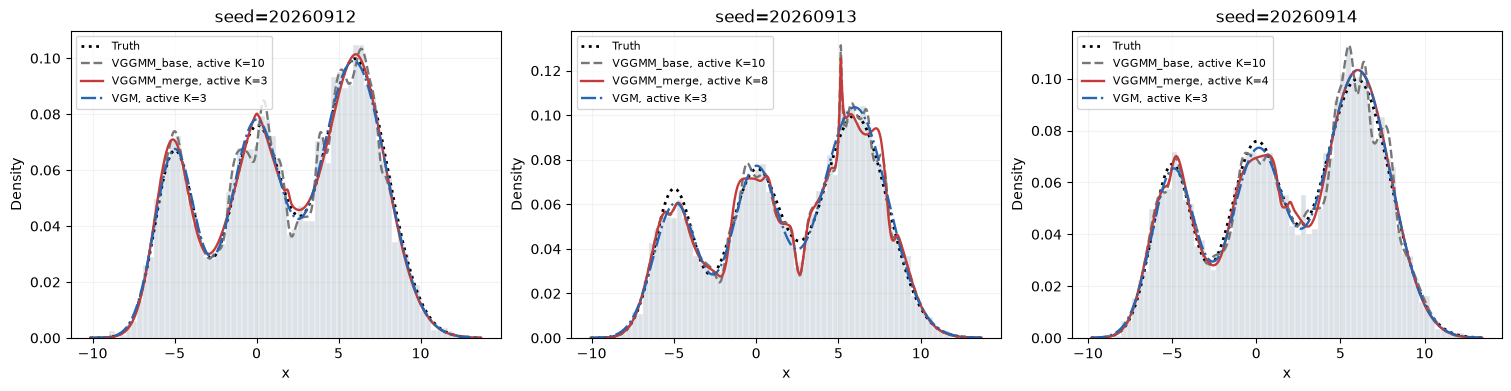

주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.
Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.
저장: results/gaussian_mixture/20261012T054405_460330Z | 실제 적합 시간 합: 186.01 s


In [12]:
# 실험 3: 순수 Gaussian 3성분. scale은 정규분포의 표준편차입니다.
gaussian_truth = gaussian_reference()
gaussian_study = run_study("gaussian_mixture",
    lambda seed: synthetic_sample(gaussian_truth, seed))


heterogeneous_mixture: seed=20260912, train=5000, test=5000, Max_K=10
    merge (0, 1): K 10->9, ELBO/n +0.000495756
    merge (7, 8): K 9->8, ELBO/n +0.000120526
    merge (2, 3): K 8->7, ELBO/n +0.00109941
    merge (2, 4): K 7->6, ELBO/n +0.000794149
VGGMM_base: K=10, test LL=-2.698523, 38.32s, converged=True | VGGMM_merge: K=6, test LL=-2.697905, 57.65s, converged=True | VGM: K=5, test LL=-2.730753, 0.67s, converged=True
heterogeneous_mixture: seed=20260913, train=5000, test=5000, Max_K=10
    merge (0, 1): K 10->9, ELBO/n +0.00144427
    merge (5, 6): K 9->8, ELBO/n +0.000960937
    merge (2, 3): K 8->7, ELBO/n +0.00125746
    merge (8, 9): K 7->6, ELBO/n +0.00166473
    merge (2, 4): K 6->5, ELBO/n +0.000326838
VGGMM_base: K=10, test LL=-2.713433, 24.67s, converged=True | VGGMM_merge: K=5, test LL=-2.713398, 43.48s, converged=True | VGM: K=6, test LL=-2.734865, 0.39s, converged=True
heterogeneous_mixture: seed=20260914, train=5000, test=5000, Max_K=10
    merge (0, 1): K 10->9, E

,Seed,Method,Active_K,IAE,ISE,Test_LL_per_obs,Negative_mass,Fit_s,Merge_extra_s,Converged,Accepted_merges,Inner_nonconverged,Failed_starts,Quadrature_OK,Status
0,20260912,VGGMM_base,10,0.065736,0.000401,-2.698523,NaN,38.317736,0.000000,True,0,0.0,0,True,ok
1,20260912,VGGMM_merge,6,0.065253,0.000499,-2.697905,NaN,57.649052,19.331233,True,4,0.0,0,True,ok
2,20260912,VGM,5,0.169029,0.003554,-2.730753,NaN,0.673588,0.000000,True,0,NaN,0,True,ok
3,20260913,VGGMM_base,10,0.069116,0.000478,-2.713433,NaN,24.673933,0.000000,True,0,0.0,0,True,ok
4,20260913,VGGMM_merge,5,0.059228,0.000386,-2.713398,NaN,43.484561,18.810551,True,5,0.0,0,True,ok
5,20260913,VGM,6,0.162219,0.002738,-2.734865,NaN,0.385539,0.000000,True,0,NaN,0,True,ok
6,20260914,VGGMM_base,10,0.066696,0.000456,-2.720244,NaN,19.110490,0.000000,True,0,0.0,0,True,ok
7,20260914,VGGMM_merge,6,0.071446,0.000512,-2.719440,NaN,46.286162,27.175592,True,4,0.0,0,True,ok
8,20260914,VGM,5,0.166986,0.003687,-2.743867,NaN,0.539386,0.000000,True,0,NaN,0,True,ok


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties
0,VGGMM_merge minus VGM,Delta_IAE,3,3,3,-0.100769,0.004546,3,0,0
1,VGGMM_merge minus VGM,Delta_ISE,3,3,3,-0.002861,0.000445,3,0,0
2,VGGMM_merge minus VGM,Delta_Test_LL_per_obs,3,3,3,0.026248,0.005904,3,0,0
3,VGGMM_merge minus VGM,Delta_Fit_s,3,3,3,48.607087,7.367153,0,3,0
4,VGGMM_merge minus VGGMM_base,Delta_IAE,3,3,3,-0.001874,0.007417,2,1,0
5,VGGMM_merge minus VGGMM_base,Delta_ISE,3,3,3,0.000021,0.000100,1,2,0
6,VGGMM_merge minus VGGMM_base,Delta_Test_LL_per_obs,3,3,3,0.000486,0.000401,3,0,0
7,VGGMM_merge minus VGGMM_base,Delta_Fit_s,3,3,3,21.772539,4.686488,0,3,0


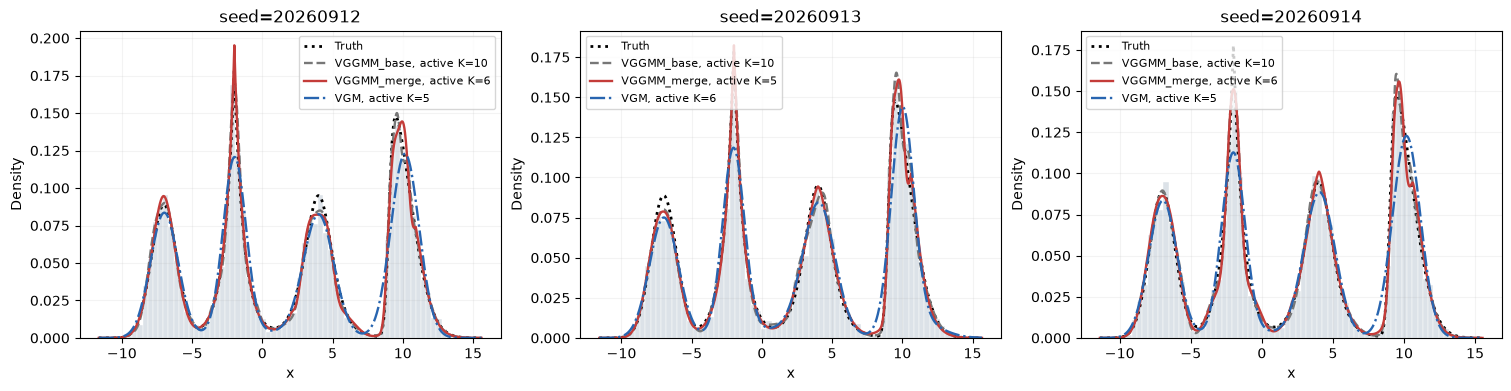

주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.
Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.
저장: results/heterogeneous_mixture/20261012T054712_228935Z | 실제 적합 시간 합: 149.02 s


In [13]:
# 실험 4: Gaussian + Laplace + Student-t + skew-normal.
# Active_K=4를 정답으로 강제하지 않고, 전체 밀도와 독립 test 표본을 평가합니다.
heterogeneous_truth = heterogeneous_reference()
heterogeneous_study = run_study("heterogeneous_mixture",
    lambda seed: synthetic_sample(heterogeneous_truth, seed))


In [14]:
# 세 실험의 결과. Δ는 VGGMM_merge − 비교방법입니다.
# ΔIAE/ΔISE/ΔFit_s는 작을수록, ΔTest_LL_per_obs는 클수록 좋습니다.
from IPython.display import display
battery_metrics = pd.concat([s["table"] for s in
    (real_study, gaussian_study, heterogeneous_study)], ignore_index=True)
battery_summary = pd.concat([s["paired_summary"].assign(Study=s["metadata"]["study_id"])
    for s in (real_study, gaussian_study, heterogeneous_study)], ignore_index=True)
display(battery_summary)
print("세 seed의 기술통계이며 일반적인 우월성의 증명은 아닙니다.")
print("실제 적합 시간 합:", sum(s["metadata"]["actual_fit_s"] for s in
    (real_study, gaussian_study, heterogeneous_study)), "s")


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties,Study
0,VGGMM_merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.004999,0.003038,0,3,0,abalone_whole_weight
1,VGGMM_merge minus VGM,Delta_Fit_s,3,3,3,32.563358,6.914575,0,3,0,abalone_whole_weight
2,VGGMM_merge minus VGGMM_base,Delta_Test_LL_per_obs,3,3,3,-0.007851,0.005767,0,3,0,abalone_whole_weight
3,VGGMM_merge minus VGGMM_base,Delta_Fit_s,3,3,3,17.686655,2.306390,0,3,0,abalone_whole_weight
4,VGGMM_merge minus VGM,Delta_IAE,3,3,3,0.018360,0.011716,0,3,0,gaussian_mixture
5,VGGMM_merge minus VGM,Delta_ISE,3,3,3,0.000192,0.000231,0,3,0,gaussian_mixture
6,VGGMM_merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.002139,0.003122,0,3,0,gaussian_mixture
7,VGGMM_merge minus VGM,Delta_Fit_s,3,3,3,57.555547,16.903386,0,3,0,gaussian_mixture
8,VGGMM_merge minus VGGMM_base,Delta_IAE,3,3,3,-0.017526,0.020546,2,1,0,gaussian_mixture
9,VGGMM_merge minus VGGMM_base,Delta_ISE,3,3,3,-0.000211,0.000241,2,1,0,gaussian_mixture


세 seed의 기술통계이며 일반적인 우월성의 증명은 아닙니다.
실제 적합 시간 합: 443.45876400101406 s


GGD_truth | Max_K=3: Active_K=3, 0.05s
GGD_truth | Max_K=10: Active_K=5, 0.78s
Gaussian_control | Max_K=3: Active_K=3, 0.08s
Gaussian_control | Max_K=10: Active_K=5, 0.47s


,Scenario,True_K,Max_K,Active_K,At_cap,IAE,ISE,Test_LL_per_obs,Fit_s,Converged,Quadrature_OK
0,GGD_truth,5,3,3,True,0.495753,0.012775,-3.141045,0.050264,True,True
1,GGD_truth,5,10,5,False,0.203888,0.002779,-2.963401,0.780411,True,True
2,Gaussian_control,5,3,3,True,0.448567,0.012506,-3.123545,0.080827,True,True
3,Gaussian_control,5,10,5,False,0.073299,0.000259,-2.945266,0.470425,True,True


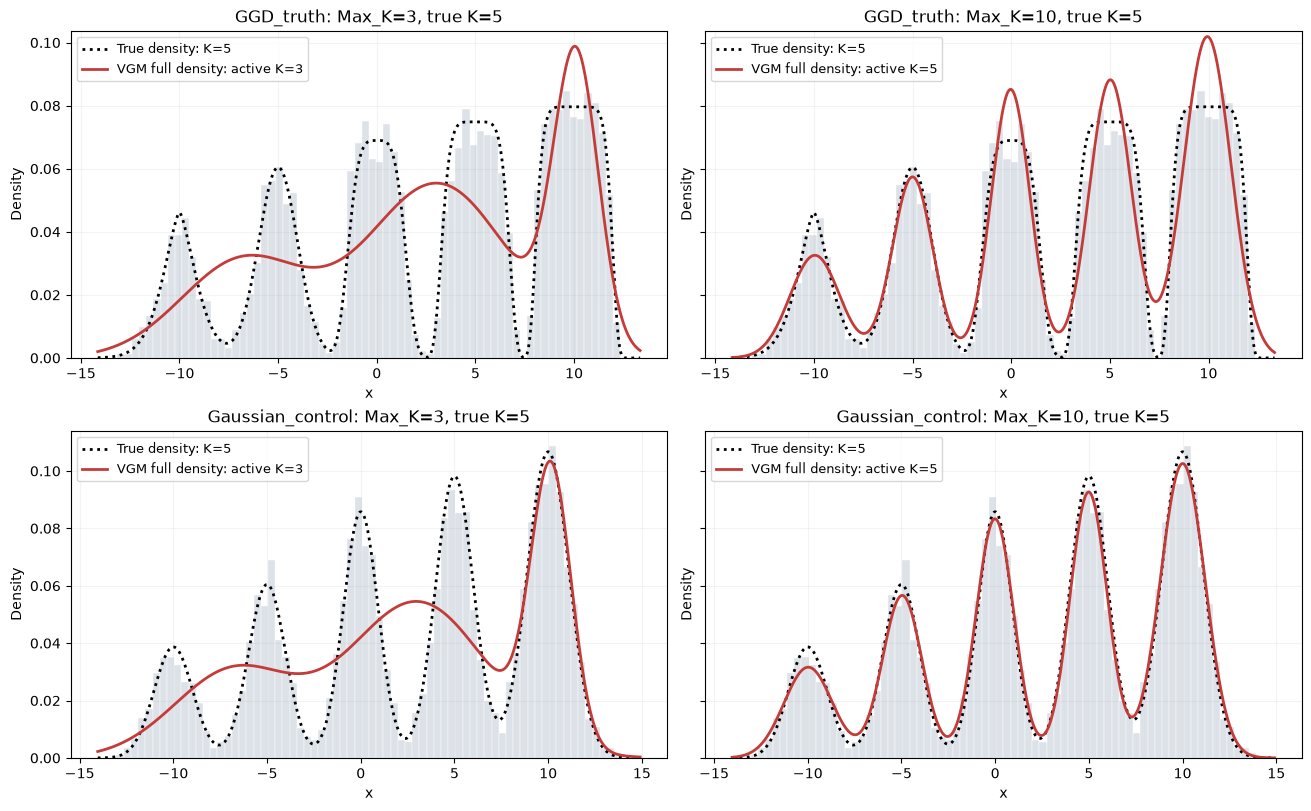

IAE·ISE는 작을수록, Test_LL_per_obs는 클수록 좋습니다.
평가는 full density입니다. Active_K는 weight > .005인 성분의 수입니다.
Converged=True는 최적화 종료 조건이며, 충분한 표현력이나 참 K 회복의 보장이 아닙니다.
Gaussian_control은 모양 차이를 제거해 성분 상한 부족의 영향을 확인하는 대조입니다.


In [16]:
# 독립 셀: 이전 노트북 정의나 VGGMM .py 파일을 불러오지 않습니다.
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad, IntegrationWarning
from scipy.special import gammaln, logsumexp
from scipy.stats import gennorm
from sklearn.mixture import BayesianGaussianMixture
from threadpoolctl import threadpool_limits
from IPython.display import display

VGM_CAP_N = 5000
VGM_CAP_SEED = 20260912
VGM_CAPS = (3, 10)
VGM_CAP_THRESHOLD = .005
VGM_GAUSSIAN_CONTROL = True  # False이면 앞선 GGD 표본만 비교합니다.


class _VGMCapDensity:
    def __init__(self, weights, means, scales, shapes):
        self.weights = np.array(weights, dtype=float, copy=True)
        self.means = np.array(means, dtype=float, copy=True)
        self.scales = np.array(scales, dtype=float, copy=True)
        self.shapes = np.array(shapes, dtype=float, copy=True)

    def logpdf(self, x):
        with np.errstate(divide="ignore"):
            return logsumexp(gennorm.logpdf(np.asarray(x).reshape(-1, 1), self.shapes,
                loc=self.means, scale=self.scales)+np.log(self.weights), axis=1)

    def pdf(self, x):
        return np.exp(self.logpdf(x))

    def cdf(self, x):
        return gennorm.cdf(np.asarray(x).reshape(-1, 1), self.shapes,
                           loc=self.means, scale=self.scales) @ self.weights

    def points(self, tail):
        p = np.array([tail, 1e-6, 1e-4, .001, .01, .1, .25, .5,
                      .75, .9, .99, .999, 1-1e-4, 1-1e-6, 1-tail])
        return gennorm.ppf(p[:, None], self.shapes, loc=self.means, scale=self.scales).ravel()

    def peak_upper(self):
        return float(np.sum(self.weights*np.exp(-np.log(2)-np.log(self.scales)
                                               -gammaln(1+1/self.shapes))))


def _vgm_cap_sample(density, seed):
    # 앞선 true_K=5 실험과 동일한 벡터화 표본 추출 순서입니다.
    rng = np.random.default_rng(seed)
    labels = rng.choice(len(density.weights), size=VGM_CAP_N, p=density.weights)
    return np.asarray(gennorm.rvs(density.shapes[labels], loc=density.means[labels],
                                 scale=density.scales[labels], random_state=rng), dtype=float)


def _vgm_cap_errors(truth, fitted, tail=1e-9):
    knots = np.unique(np.r_[truth.points(tail), fitted.points(tail)])
    if not np.isfinite(knots).all():
        raise FloatingPointError("밀도 평가 분위수가 유한하지 않습니다.")
    left, right = float(knots[0]), float(knots[-1])
    def delta(t):
        return float(fitted.pdf([t])[0]-truth.pdf([t])[0])
    options = dict(points=knots[1:-1], epsabs=1e-7, epsrel=1e-5, limit=2000)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", IntegrationWarning)
        iae, iae_error = quad(lambda t: abs(delta(t)), left, right, **options)
        ise, ise_error = quad(lambda t: delta(t)**2, left, right, **options)
    def tail_mass(density):
        c = density.cdf([left, right])
        return float(np.clip(c[0]+1-c[1], 0, 1))
    tt, tf = tail_mass(truth), tail_mass(fitted)
    numerical_ok = (not any(issubclass(w.category, IntegrationWarning) for w in caught)
                    and iae_error <= 1e-7+1e-5*abs(iae) and ise_error <= 1e-7+1e-5*abs(ise))
    return dict(IAE=iae, ISE=ise, IAE_quad_error=iae_error, ISE_quad_error=ise_error,
        IAE_tail_upper=tt+tf, ISE_tail_upper=truth.peak_upper()*tt+fitted.peak_upper()*tf,
        Quadrature_OK=bool(numerical_ok), Evaluation_warnings=[str(w.message) for w in caught])


vgm_cap_weights = np.array([.10, .15, .20, .25, .30])
vgm_cap_means = np.array([-10., -5., 0., 5., 10.])
vgm_cap_scales = np.array([1.2, 1.4, 1.6, 1.8, 2.0])  # GGD scale a, not normal SD
vgm_cap_shapes = np.array([1.5, 2., 4., 6., 8.])
vgm_cap_truths = {"GGD_truth": _VGMCapDensity(
    vgm_cap_weights, vgm_cap_means, vgm_cap_scales, vgm_cap_shapes)}
if VGM_GAUSSIAN_CONTROL:
    # Pure Gaussian control: match each original component's mean, weight and variance.
    vgm_cap_sigmas = vgm_cap_scales*np.exp(.5*(
        gammaln(3/vgm_cap_shapes)-gammaln(1/vgm_cap_shapes)))
    vgm_cap_truths["Gaussian_control"] = _VGMCapDensity(
        vgm_cap_weights, vgm_cap_means, np.sqrt(2)*vgm_cap_sigmas, np.full(5, 2.))

def _run_vgm_cap_experiment():
    vgm_cap_samples, vgm_cap_models, vgm_cap_densities = {}, {}, {}
    vgm_cap_records = []
    for scenario, truth in vgm_cap_truths.items():
        x = _vgm_cap_sample(truth, VGM_CAP_SEED)
        x_test = _vgm_cap_sample(truth, VGM_CAP_SEED+1000)
        x.setflags(write=False)
        vgm_cap_samples[scenario] = dict(train=x, test=x_test)
        for cap in VGM_CAPS:
            estimator = BayesianGaussianMixture(n_components=cap, covariance_type="full",
                weight_concentration_prior_type="dirichlet_process", weight_concentration_prior=.001,
                init_params="kmeans", n_init=2, random_state=27, max_iter=1500, tol=1e-3, reg_covar=1e-6)
            with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                tick = perf_counter()
                estimator.fit(x.copy().reshape(-1, 1))  # Truth/test data never enter fit.
                seconds = perf_counter()-tick
            weights = estimator.weights_/estimator.weights_.sum()
            # Full posterior-parameter plug-in Gaussian mixture, including small weights.
            # A Gaussian SD sigma becomes GGD scale a=sqrt(2)*sigma at b=2.
            fitted = _VGMCapDensity(weights, estimator.means_[:, 0],
                np.sqrt(2*estimator.covariances_[:, 0, 0]), np.full(cap, 2.))
            active = weights > VGM_CAP_THRESHOLD
            assert len(weights) == cap and np.isclose(weights.sum(), 1.)
            vgm_cap_models[(scenario, cap)] = estimator
            vgm_cap_densities[(scenario, cap)] = fitted
            vgm_cap_records.append(dict(Scenario=scenario, Method="VGM", True_K=5, Max_K=cap,
                Active_K=int(active.sum()), At_cap=bool(active.all()),
                Inactive_mass=float(weights[~active].sum()), **_vgm_cap_errors(truth, fitted),
                Test_LL_per_obs=float(fitted.logpdf(x_test).mean()), Fit_s=seconds,
                Converged=bool(estimator.converged_), Iterations=int(estimator.n_iter_),
                Fit_warnings=[str(w.message) for w in caught]))
            print(f"{scenario} | Max_K={cap}: Active_K={active.sum()}, {seconds:.2f}s", flush=True)

    vgm_cap_table = pd.DataFrame(vgm_cap_records)
    display(vgm_cap_table[["Scenario", "True_K", "Max_K", "Active_K", "At_cap", "IAE", "ISE",
        "Test_LL_per_obs", "Fit_s", "Converged", "Quadrature_OK"]])

    vgm_cap_fig, vgm_cap_axes = plt.subplots(len(vgm_cap_truths), len(VGM_CAPS),
        figsize=(13, 4*len(vgm_cap_truths)), squeeze=False, sharex="row", sharey="row",
        layout="constrained")
    for row, (scenario, truth) in enumerate(vgm_cap_truths.items()):
        x = vgm_cap_samples[scenario]["train"]
        grid = np.linspace(x.min()-1., x.max()+1., 2400)
        bins = np.histogram_bin_edges(x, bins=70)
        for col, cap in enumerate(VGM_CAPS):
            ax, fitted = vgm_cap_axes[row, col], vgm_cap_densities[(scenario, cap)]
            ax.hist(x, bins=bins, density=True, color="#dce2e8", edgecolor="white", linewidth=.3)
            ax.plot(grid, truth.pdf(grid), "k:", lw=2, label="True density: K=5")
            active_k = int(np.sum(fitted.weights > VGM_CAP_THRESHOLD))
            ax.plot(grid, fitted.pdf(grid), color="#c43c39", lw=2, label=f"VGM full density: active K={active_k}")
            ax.set(title=f"{scenario}: Max_K={cap}, true K=5", xlabel="x", ylabel="Density")
            ax.set_ylim(bottom=0)
            ax.grid(alpha=.15)
            ax.legend(fontsize=9)
    plt.show()

    print("IAE·ISE는 작을수록, Test_LL_per_obs는 클수록 좋습니다.")
    print("평가는 full density입니다. Active_K는 weight > .005인 성분의 수입니다.")
    print("Converged=True는 최적화 종료 조건이며, 충분한 표현력이나 참 K 회복의 보장이 아닙니다.")
    print("Gaussian_control은 모양 차이를 제거해 성분 상한 부족의 영향을 확인하는 대조입니다.")

    return vgm_cap_table, vgm_cap_samples, vgm_cap_models, vgm_cap_densities, vgm_cap_fig


(vgm_cap_table, vgm_cap_samples, vgm_cap_models, vgm_cap_densities,
 vgm_cap_fig) = _run_vgm_cap_experiment()
